> ## 🎤 강사 스크립트 · 이 강사용 노트북 사용법
>
> 이 노트북은 **학생용 `D26_실시간오디오_실습.ipynb`의 모든 셀을 그대로 담고**, 사이사이에 **🎤 강사 스크립트 셀**을 끼워 넣은 것입니다. 수업 화면에는 학생용을, 강사 화면에는 이 노트북을 띄우세요.
>
> | 표시 | 뜻 |
> |---|---|
> | 🎯 | 이 블록에서 학생이 가져가야 할 한 가지 |
> | 🗣️ | 그대로 읽어도 되는 강사 멘트 |
> | 🍎 | 일상 비유 |
> | 🖥️ | 화면 시연 |
> | ❓ | 학생에게 던지는 질문 → 예상 답 |
> | 🆘 | 빈칸에서 막힌 학생에게 주는 힌트 |
> | ⚠️ | 자주 막히는 지점 · 오개념 · 오류 |
> | 🎧 | 반 전체가 같이 들을 소리 (스피커) |
> | ➡️ | 다음 블록으로 넘어가는 연결 멘트 |
>
> **오늘의 수업 방향**: 6주차 첫날. LLM은 잠시 내려놓고 **'소리가 네트워크를 건너는 방법'** 에 집중합니다. 핵심 메시지는 **"조각으로 흘려보낸다 → 네트워크는 들쭉날쭉하다 → 늦은 조각은 버리고 메운다 → 압축해서 작게 보낸다 → 서버끼리는 WebSocket, 사람 쪽은 WebRTC"** 입니다. 칠판에 쓰는 식은 **프레임 샘플 = SR × ms / 1000**, **재생 시점 = 보낸 시각 + 재생 지연**, **통화당 대역폭 = (코덱 + 머리말) × 2** 세 개입니다.
>
> > 🍎 **하루를 꿰는 비유: 택배 vs 수도관.** batch는 택배(다 싸서 한 번에), streaming은 수도관(틀면 바로). 수도관에는 압력(대역폭) · 수압 흔들림(지터) · 새는 곳(손실)이 있고, 물탱크(지터 버퍼)로 고르게 만든다.
>
> > 🔒 오늘의 서버 · 연결은 모두 Colab 안 127.0.0.1. 외부 공개는 7주차.
>
> > 💡 정답 · 예상 출력 · 힌트는 이 노트북에만 있습니다. **학생에게 배포하지 마세요.**

> ## 🎤 강사 스크립트 · 하루 시간표와 수업 전 점검
>
> #### 하루 시간표 (50분 수업 + 10분 쉬는 시간)
> | 시간 | 교시 | 내용 | 빈칸 | 애니메이션 | 슬라이드 |
> |---|---|---|---|---|---|
> | 0:00–0:50 | 1교시 | 도입, Part 0 설치, Part 1 프레임 · 비트레이트 · batch vs streaming | 1 · 2 | D26-1 · 2 · 3 | p.1 ~ 6 |
> | 1:00–1:50 | 2교시 | Part 2 네트워크 흉내 · 지터 버퍼 · 적응형 · TCP vs UDP | 3 · 4 · 5 | D26-4 · 5 | p.7 ~ 11 |
> | 2:00–2:50 | 3교시 | Part 3 Opus, Part 4 WebSocket 서버 | 6 · 7 | D26-6 · 7 | p.12 ~ 15 |
> | 3:00–3:50 | 4교시 | Part 5 WebRTC, Part 6 선택 · 대역폭, Part 7 정리 | 8 · 9 | D26-8 · 9 | p.16 ~ 20 |
>
> **진도가 밀릴 때 줄이는 순서** (빈칸 실습은 줄이지 않습니다)
> 1. Part 3 코덱 비교표를 Opus 6 · 24k와 μ-law만 (Whisper 호출이 가장 오래 걸림)
> 2. Part 4 Opus 전송 비교 셀은 강사 시연만
> 3. 적응형 버퍼(빈칸 5) 결과 토론 생략
>
> #### 수업 전 점검 (전날)
> - [ ] 처음부터 끝까지 한 번 실행(약 10 ~ 15분, T4). Part 2 표 · 소리, Part 3 코덱표, Part 4 왕복 시간, Part 5 RTP 통계 캡처
> - [ ] **Part 5 WebRTC**: 'WebRTC로 건너온 소리'가 들리고 보낸 · 받은 패킷이 같으면 OK. 미디어가 안 흐르면 노트북이 안내문을 띄움 → 그 경우 SDP · 연결 단계 설명 + 애니메이션 D26-8로 진행
> - [ ] 스피커 준비 (Part 2 끊김 소리 · Part 3 코덱 소리를 반 전체가 같이 듣기)
> - [ ] [animation.html](https://imguru-mooc.github.io/AI_Voice/day26/animation.html) · [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day26/worksheet.html) 탭 열기
>
> #### 오늘 학생들이 가장 많이 막히는 곳
> | 위치 | 증상 | 대응 |
> |---|---|---|
> | Part 0 | `aiortc` 설치 중 `av` 버전 메시지 | 대부분 무시 가능 · 설치 셀 한 번 더 |
> | Part 1 | 빈칸 2에 `2` (바이트) 입력 | kbps는 **비트** → 16 |
> | Part 2 | 늦은 조각이 100% | 빈칸 4에 `send` 등 → `deadline` |
> | Part 3 | `av.error` | 빈칸 6에 `kbps`만(24) → 24 bps가 됨 → `kbps * 1000` |
> | Part 4 | `ConnectionRefusedError` | 서버 셀을 안 돌렸거나 포트 → 🚀 셀 다시 |
> | Part 4 | 셀이 끝나지 않음 | 서버가 꺼짐 → `ws_server.log` 확인, 커널 재시작 후 Part 4부터 |
> | Part 5 | 30초 넘게 멈춤 | `aioice` 버전 확인(0.10.2) · 런타임 재시작 후 설치 셀부터 |
> | Part 5 | 실제 kbps가 50 이상 | 정상: aiortc의 기본 Opus 비트레이트가 높고 RTP 머리말이 포함됨 |

# D26. 실시간 오디오 기초: Streaming · Buffer · Jitter · WebSocket vs WebRTC · Opus  —  🎤 강사용

**음성 AI 전문가 과정 (160h) | 6주차 M6 실시간 음성 파이프라인 (Pipecat · LiveKit) | 4시간**

## 학습 목표
1. **batch(다 모아서)와 streaming(조각으로)** 의 차이를 설명하고, 20 ms **프레임** 크기와 **비트레이트**를 계산한다.
2. 네트워크를 흉내 내어 **지연 · 지터(jitter) · 손실**이 소리에 주는 영향을 듣고, **지터 버퍼** 크기와 늦은 조각 비율의 맞바꿈을 잰다.
3. 조각 하나를 잃었을 때 **TCP(WebSocket)** 와 **UDP(WebRTC · RTP)** 가 어떻게 다르게 행동하는지(**head-of-line blocking**) 비교한다.
4. **Opus** 코덱으로 음성을 6 ~ 64 kbps로 압축 · 복원하고, 크기 · 음질 · 받아쓰기 정확도(CER)를 비교한다.
5. **WebSocket** 서버에 20 ms 조각을 실시간 속도로 보내고 이벤트(말 시작 · 끝)를 받아, 왕복 시간을 잰다.
6. **WebRTC**(aiortc) 두 피어를 연결해 **offer · answer · ICE · RTP**를 직접 보고, 실제로 Opus 소리가 흐르는지 확인한다.

## 오늘의 실습 흐름
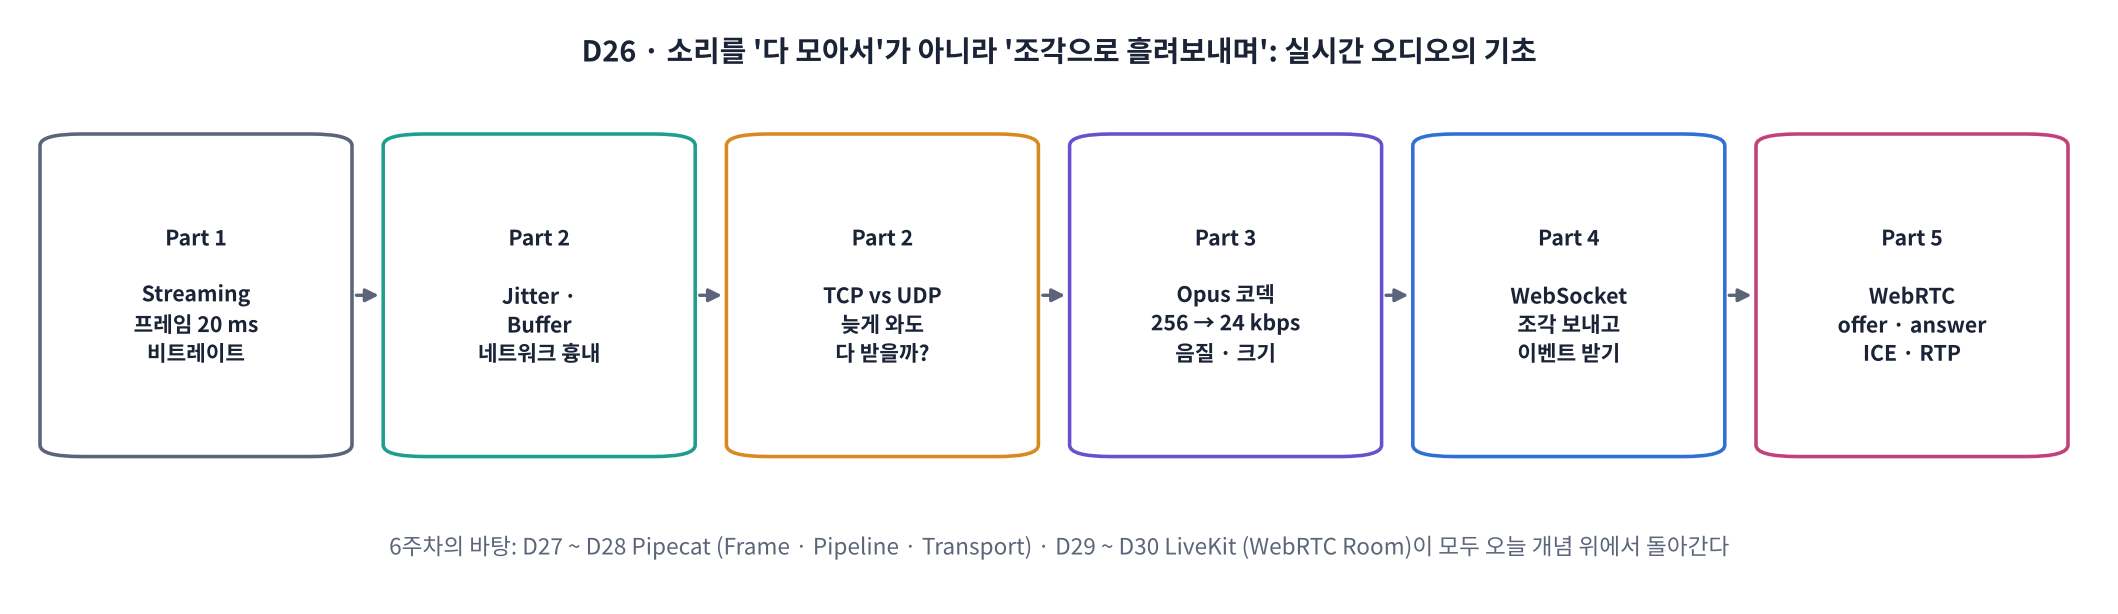

| 교시 | 내용 | 실습 | 산출물 |
|---|---|---|---|
| 1교시 | 실시간이 왜 필요한가, 프레임 · 비트레이트, batch vs streaming | Part 0 ~ 1, 워크시트 1교시 | 형식별 kbps 표 · 첫 반응 시간 |
| 2교시 | 네트워크 흉내: 지터 · 지터 버퍼 · 손실 · TCP vs UDP | Part 2, 워크시트 2교시 | 버퍼 크기별 늦은 조각 표 · 소리 비교 |
| 3교시 | Opus 코덱, WebSocket 스트리밍 서버 | Part 3 ~ 4, 워크시트 3교시 | 비트레이트별 크기 · CER 표 · 왕복 시간 |
| 4교시 | WebRTC 연결 해부, 둘 중 무엇을 쓸까, 정리 | Part 5 ~ 7, 워크시트 4교시 | SDP · RTP 통계 · 대역폭 계산표 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day26/animation.html) | 프레임(D26-2) · 지터 버퍼(D26-4) · TCP vs UDP(D26-5) · WebRTC 연결(D26-8) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day26/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령, `%%writefile` 셀은 셀 내용을 파일로 저장합니다.
- 🧩 **빈칸 실습** 셀은 `____`를 채우고 실행하면 ✅ 또는 ❌가 나옵니다. 🔑 **정답 및 해설 보기**를 누르면 정답이 펼쳐집니다.
- ✏️ 표시 셀은 숫자(지터 · 손실 · 버퍼 · 비트레이트)를 **직접 바꿔** 다시 실행해 보는 셀입니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 소리로 확인 |

> ⚙️ **런타임 → T4 GPU** (Whisper로 코덱 음질을 잴 때 사용, CPU도 가능). 오늘은 **LLM · API 키가 필요 없습니다.** 새로 설치하는 것은 `websockets`(WebSocket) · `aiortc`(파이썬 WebRTC) · PyAV(`av`, Opus 코덱)입니다.
>
> 🔒 오늘의 서버 · 연결은 모두 **이 Colab 안(127.0.0.1)** 에서만 열립니다. 바깥에 공개하는 서버는 7주차(인증 · HTTPS)에서 다룹니다.

> 🎬 **애니메이션 D26-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#flow) — Part 1~7 로드맵과 시간 계획

> ## 🎤 강사 스크립트 · 도입  ⏱️ 5분
>
> 🎯 **6주차는 '흘려보내는' 비서.**
>
> 🗣️ "지난주 비서는 말이 끝나야 듣고, 답이 다 만들어져야 말했습니다. 측정해 보니 첫 소리가 1초를 훌쩍 넘었죠. 이번 주에는 소리를 조각으로 흘려보내서, 듣는 중에 처리하고 만드는 중에 말하는 비서로 바꿉니다. 오늘은 그 바탕, **소리가 네트워크를 건너는 법**입니다."
>
> 🖥️ [D26-1 오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#flow). 오늘은 API 키 없음.

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D18 ~ D25와 같은 방식)**: Colab 기본 패키지 버전을 고정하고 필요한 것만 추가합니다. `aioice`(WebRTC의 길 찾기 ICE 구현)는 **수업에서 검증한 0.10.2**로 고정합니다(최신 0.11에서는 같은 컴퓨터 안 두 피어 연결이 멈추는 경우가 있었음).

> ## 🎤 강사 스크립트 · Part 0  ⏱️ 5분
>
> 🖥️ 설치 → import(버전 줄에 `aioice 0.10.2` 확인) → 실험 소리 만들기.
>
> 🗣️ "오늘은 LLM이 없습니다. TTS로 실험 소리를 하나 만들고, 그 소리를 쪼개고 · 흔들고 · 압축하고 · 보내 봅니다."

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 1 ~ 2분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "protobuf", "requests",
        "click", "filelock", "rich", "typer", "pydantic", "httpx"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))
!pip install -q -c colab_constraints.txt websockets aiortc "aioice==0.10.2"
!pip install -q -c colab_constraints.txt silero-vad uroman jiwer
!apt-get -qq -y install ffmpeg > /dev/null
print("✅ 설치 완료")

In [ ]:
import os, re, io, sys, json, time, random, socket, asyncio, fractions, subprocess, warnings, logging
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import av
import matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown
import importlib.metadata as md
warnings.filterwarnings("ignore")
for name in ["transformers", "aiortc", "aioice", "websockets"]:
    logging.getLogger(name).setLevel(logging.ERROR)

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 16000
print(" · ".join(f"{p} {md.version(p)}" for p in ["torch", "transformers", "av", "websockets", "aiortc", "aioice"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 가능)")

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    display(Audio(y, rate=sr))

def silence(sec, sr=SR):
    return np.zeros(int(sec * sr), np.float32)

def free_port():                                         # 비어 있는 포트 번호 하나
    s = socket.socket(); s.bind(("127.0.0.1", 0)); p = s.getsockname()[1]; s.close(); return p

def wait_port(port, sec=15):
    for _ in range(int(sec * 10)):
        try:
            socket.create_connection(("127.0.0.1", port), timeout=0.2).close(); return True
        except OSError:
            time.sleep(0.1)
    return False

In [ ]:
# 🔊 오늘의 실험 소리: MMS-TTS로 만든 사용자 말 (D16 · D22와 같은 TTS) + 받아쓰기용 Whisper · 끝점용 Silero VAD
from transformers import AutoTokenizer, VitsModel, WhisperProcessor, WhisperForConditionalGeneration
from silero_vad import load_silero_vad, VADIterator
import uroman as ur, jiwer
tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts_model = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
U = ur.Uroman()
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()
vad = load_silero_vad()

def tts(text, seed=0):
    set_seed(seed)
    enc = tts_tok(U.romanize_string(text), return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        return to_np(tts_model(**enc).waveform[0])

def stt(y):
    feats = asr_proc.feature_extractor(to_np(y), sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=96)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def cer(ref, hyp):                                       # D10과 같은 글자 오류율 (띄어쓰기 · 문장부호 무시)
    n = lambda s: re.sub(r"[^가-힣a-zA-Z0-9]", "", s)
    return jiwer.cer(n(ref), n(hyp) or "∅")

SAY = "안녕하세요 한빛치과죠 다음 주 수요일 오후 두 시에 스케일링 예약하고 싶어요"
VOICE = np.concatenate([silence(0.5), tts(SAY), silence(0.8)]).astype(np.float32)
VOICE = VOICE / (np.abs(VOICE).max() + 1e-9) * 0.8
play(VOICE, SR, "오늘의 실험 소리 (합성 목소리)")
print("받아쓰기 (원음):", stt(VOICE))

> ## 🎤 강사 스크립트 · 실험 소리  ⏱️ 2분
>
> ✅ 🎧 약 4 ~ 5초 · `받아쓰기 (원음): 안녕하세요 한빛치과죠 …` (Whisper small). 이 받아쓰기가 Part 3 코덱 비교의 기준.

## Part 1. 실시간이란? batch vs streaming, 프레임과 비트레이트

지금까지(D21 ~ D25)의 비서는 **말이 다 끝나야** 받아쓰기를 시작하고, **답이 다 만들어져야** 말했습니다. 실시간 음성은 소리를 **작은 조각(프레임)** 으로 잘라 **만들어지는 즉시 흘려보냅니다**.

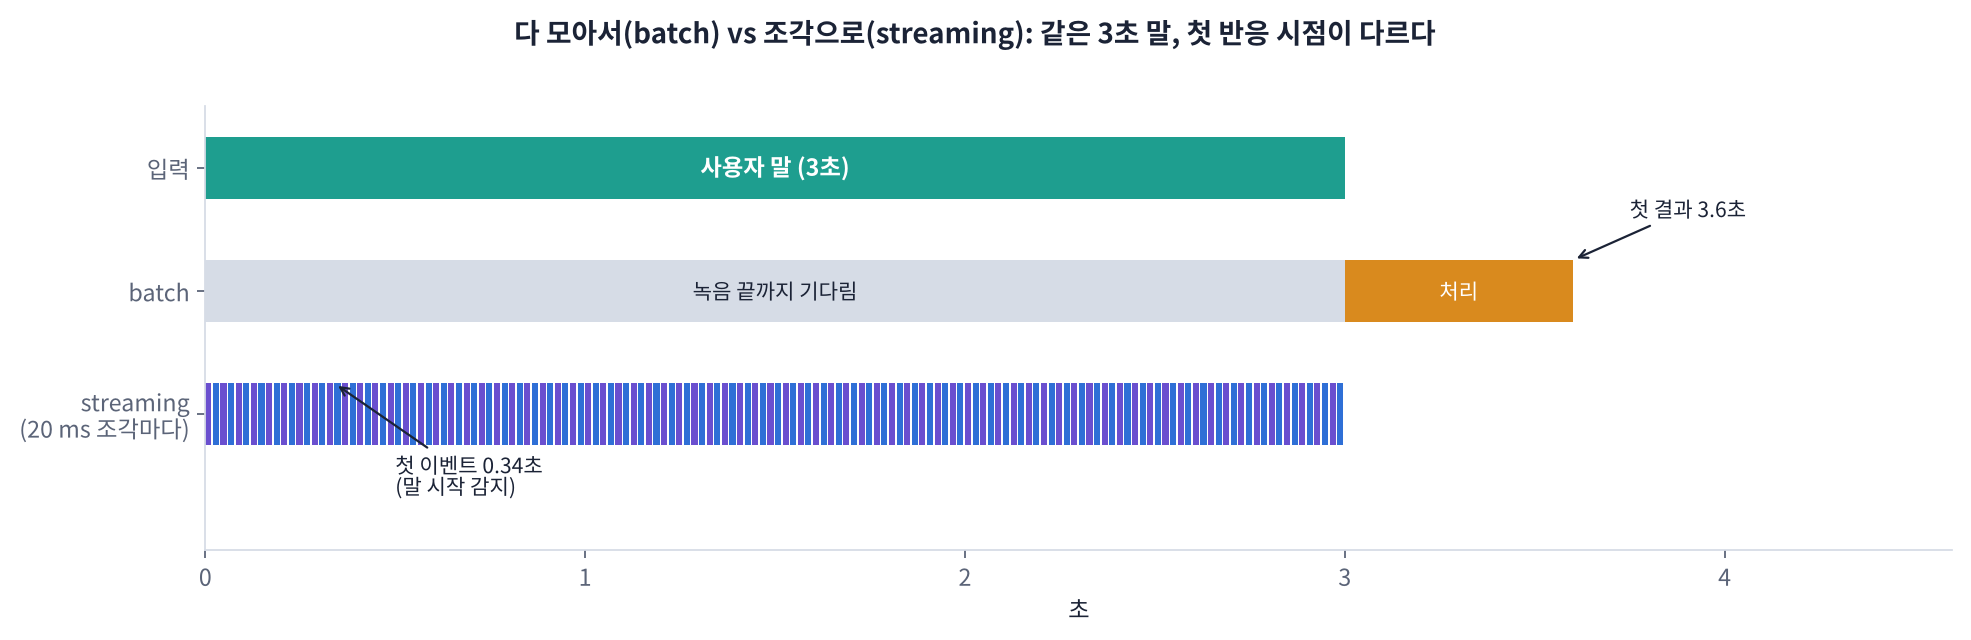

> 💬 **쉽게 말하면**: 편지(batch)는 다 쓰고 나서 부치고, 전화(streaming)는 말하는 즉시 건너갑니다.

> 🍎 **비유: 수도관과 물통.** 물통(batch)은 다 채운 뒤에 옮기고, 수도관(streaming)은 틀면 바로 나옵니다. 대신 수도관은 **압력(대역폭)** 과 **끊김(지터 · 손실)** 을 신경 써야 합니다.

| 용어 | 뜻 | 오늘 값 |
|---|---|---|
| **프레임 (frame)** | 한 번에 보내는 소리 조각 | 20 ms (음성 통신의 표준적인 크기) |
| **샘플 수 / 프레임** | 샘플링 레이트 × 프레임 길이 | 16 kHz × 20 ms = 320 샘플 |
| **비트레이트** | 1초에 보내는 비트 수 | PCM16 16 kHz 모노 = 256 kbps |
| **패킷 (packet)** | 네트워크로 보내는 한 덩어리 (보통 프레임 1개 + 머리말) | 1초에 50개 |

> 📐 **핵심 식 하나**: **비트레이트(bps) = 샘플링 레이트 × 비트 깊이 × 채널 수**, **프레임 샘플 수 = 샘플링 레이트 × 프레임(ms) / 1000**

> 🎬 **애니메이션 D26-2:** [프레임 · 비트레이트 계산기](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#frame) — 샘플링 레이트 · 비트 · 프레임 길이를 바꾸며 크기와 패킷 수 보기
> 🎬 **애니메이션 D26-3:** [batch vs streaming](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#stream) — 같은 말을 다 모아서 vs 조각으로 처리할 때 첫 반응 시점 비교

### 🧩 빈칸 실습 1 · 2: 프레임 크기와 비트레이트 (D2 복습)
- 빈칸 1: 20 ms 프레임의 샘플 수 = `SR × ____ / 1000` (프레임 길이 변수)
- 빈칸 2: 16 kHz · **16비트** 모노 PCM의 kbps = `SR × ____ / 1000`

> ## 🎤 강사 스크립트 · Part 1  ⏱️ 8분
>
> 🎯 **20 ms 프레임, 256 kbps.**
>
> 🖥️ [D26-2 프레임 계산기](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#frame): 16 kHz → 48 kHz, 16비트 → 8비트, 20 → 60 ms를 바꾸며 숫자 변화.
>
> 🖥️ [D26-3 batch vs streaming](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#stream)
>
> ❓ "전화는 왜 8 kHz였을까?" → 사람 말의 중요한 정보가 4 kHz 아래 + 대역폭 아끼기 (Nyquist, D2).

In [ ]:
# 🧩 빈칸 실습 1 · 2: 프레임 크기와 비트레이트
FRAME_MS = 20                                            # ✏️ 10 · 20 · 40으로 바꿔 보세요
FRAME = int(SR * ____ / 1000)                                                     # 빈칸 1: 프레임 하나의 샘플 수
BITS = 16
pcm_kbps = SR * ____ / 1000                                                       # 빈칸 2: 16 kHz · 16비트 모노 PCM

def to_frames(y, n=FRAME):                               # 소리 → 프레임 목록 (끝의 모자란 조각은 0으로 채움)
    y = np.pad(y, (0, (-len(y)) % n))
    return y.reshape(-1, n)

F = to_frames(VOICE)
FORMATS = pd.DataFrame([
    dict(형식="PCM16 48 kHz (WebRTC 내부 원음)", kbps=48000 * 16 / 1000),
    dict(형식="PCM16 16 kHz (Whisper 입력)", kbps=pcm_kbps),
    dict(형식="μ-law 8 kHz (전화 G.711)", kbps=8000 * 8 / 1000),
    dict(형식="Opus 24 kbps (Part 3)", kbps=24.0)])
FORMATS["프레임당 바이트"] = (FORMATS["kbps"] * 1000 / 8 * FRAME_MS / 1000).round(0).astype(int)
FORMATS["1분 크기 (MB)"] = (FORMATS["kbps"] * 1000 / 8 * 60 / 1e6).round(2)
print(f"프레임 {FRAME_MS} ms = {FRAME} 샘플 = {FRAME * 2} 바이트(PCM16) · 1초에 {1000 // FRAME_MS}개 · 오늘 소리 = {len(F)} 프레임")
display(FORMATS)
check(FRAME == SR * FRAME_MS // 1000 and pcm_kbps == 256 and F.shape[1] == FRAME, hint="빈칸 1 = FRAME_MS, 빈칸 2 = BITS (16)")

> ## 🎤 강사 스크립트 · 🧩 빈칸 1 · 2  ⏱️ 5분
>
> 🆘 빈칸 1: "몇 ms 프레임? 그 변수 이름" → `FRAME_MS`. 빈칸 2: "kbps는 비트! 16비트" → `BITS`.
>
> ✅ `프레임 20 ms = 320 샘플 = 640 바이트(PCM16) · 1초에 50개`, 형식표(768 · 256 · 64 · 24 kbps), ✅.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
FRAME = int(SR * FRAME_MS / 1000)   # 빈칸 1 → 320 샘플
pcm_kbps = SR * BITS / 1000         # 빈칸 2 → 256 kbps
```

**해설**: 16,000 샘플/초 × 0.02초 = 320 샘플, 한 샘플이 16비트(2바이트)이므로 프레임 하나는 640바이트입니다. 1초에 50프레임 × 640바이트 = 32,000바이트 = 256 kbps. 같은 말을 Opus 24 kbps로 보내면 **10분의 1 이하**가 됩니다(Part 3). 프레임을 길게 하면 패킷 수(머리말 비용)는 줄지만 **한 프레임만큼 기다려야** 보낼 수 있으므로 지연이 늘어납니다.

</details>

In [ ]:
# ⏱️ batch vs streaming: 같은 말에서 '말 시작'을 언제 알 수 있나 (Silero VAD, 32 ms 조각 = 512 샘플)
CH = 512
it = VADIterator(vad, sampling_rate=SR, min_silence_duration_ms=300)
events = []
for i in range(0, len(VOICE) - CH + 1, CH):
    ev = it(torch.from_numpy(np.ascontiguousarray(VOICE[i:i + CH])))
    if ev:                                               # 조각이 '도착한 시각' = 그 조각의 끝 시각
        events.append(dict(이벤트="말 시작" if "start" in ev else "말 끝", 알게된시각=round((i + CH) / SR, 2)))
it.reset_states()
t = time.perf_counter(); text = stt(VOICE); t_stt = time.perf_counter() - t
dur = len(VOICE) / SR
display(pd.DataFrame(events))
print(f"streaming: 첫 이벤트 {events[0]['알게된시각'] if events else '-'}초 (말이 들어오는 중에)")
print(f"batch    : 녹음 {dur:.2f}초가 끝난 뒤 받아쓰기 {t_stt:.2f}초 → 첫 결과 {dur + t_stt:.2f}초")
plt.figure(figsize=(9, 2.4))
plt.plot(np.arange(len(VOICE)) / SR, VOICE, color="#1E9E8F", lw=0.6)
for e in events: plt.axvline(e["알게된시각"], color="#C2417A" if e["이벤트"] == "말 시작" else "#6A4FCF", ls="--")
plt.axvline(dur + t_stt, color="#D98A1E", lw=2); plt.xlabel("seconds"); plt.title("dashed = streaming VAD events · orange = batch first result"); plt.tight_layout(); plt.show()

> ## 🎤 강사 스크립트 · batch vs streaming  ⏱️ 5분
>
> ✅ 예상: streaming 첫 이벤트 0.5 ~ 0.7초, batch 첫 결과 = 녹음 길이 + 받아쓰기 시간(약 4 ~ 6초).
>
> 🗣️ "같은 말인데 하나는 0.5초에 반응하고, 하나는 5초 뒤에 반응합니다. 이 차이가 6주차 전체의 이유입니다."

**❓ 생각해 보기**: 프레임을 20 ms 대신 200 ms로 키우면 무엇이 좋아지고 무엇이 나빠질까요?

<details>
<summary>답 보기</summary>

**좋아지는 것**: 1초에 보내는 패킷 수가 50개 → 5개로 줄어 **머리말(IP · UDP · RTP 약 40바이트) 비용**과 CPU 부담이 줄고, 코덱 압축 효율도 조금 좋아집니다. **나빠지는 것**: 조각을 다 채워야 보낼 수 있으니 **200 ms를 기다린 뒤에야** 출발합니다(지연 +180 ms). 그리고 패킷 하나를 잃으면 **200 ms가 통째로** 빕니다. 그래서 음성 통신은 보통 10 ~ 40 ms, 대개 **20 ms**를 씁니다.

</details>

> 📝 **워크시트 1교시** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day26/worksheet.html) — 실시간 · 프레임 · 비트레이트 10문항

> ## 🎤 강사 스크립트 · 프레임 크기 토론 + 워크시트 1교시  ⏱️ 6분
>
> ❓ 생각해 보기(200 ms 프레임) → 머리말 · CPU ↓ / 지연 · 손실 영향 ↑.
>
> 🖥️ [worksheet.html 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day26/worksheet.html) 10문항.

## Part 2. 네트워크 흉내: 지연 · 지터 · 손실, 그리고 지터 버퍼

보내는 쪽은 20 ms마다 **고르게** 조각을 보내지만, 인터넷을 건너면 도착 간격이 **들쭉날쭉**해집니다. 이것이 **지터(jitter)** 입니다. 받는 쪽은 조각을 바로 재생하지 않고 **잠깐 모아 두었다가(지터 버퍼)** 일정한 간격으로 재생합니다.

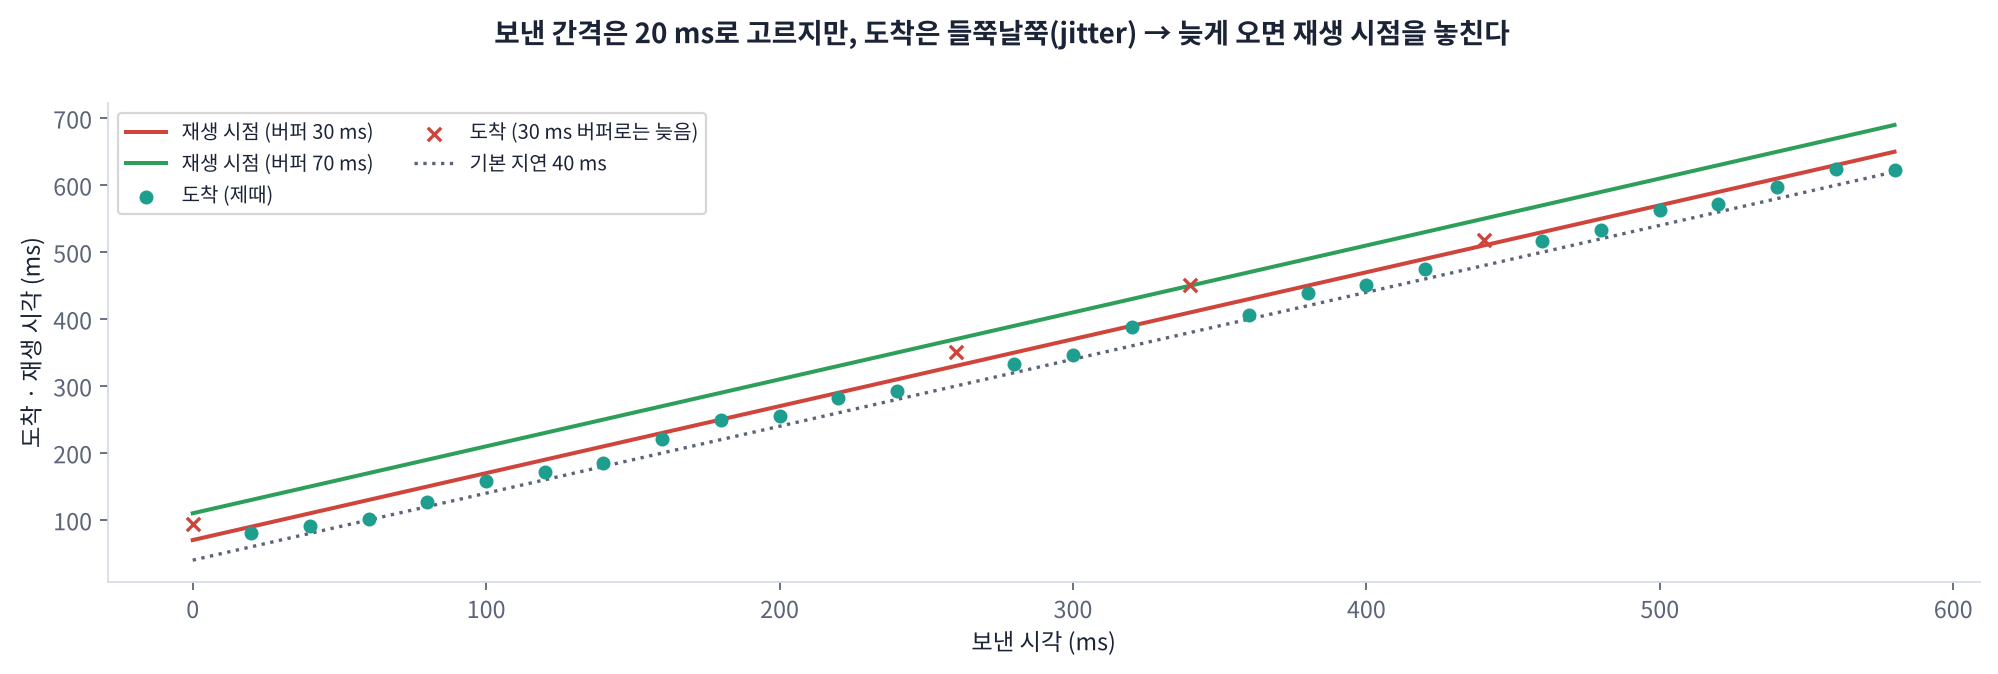

| 용어 | 뜻 |
|---|---|
| **지연 (latency)** | 보낸 뒤 도착까지 걸린 시간 (기본 지연 + 들쭉날쭉한 부분) |
| **지터 (jitter)** | 도착 간격의 흔들림 |
| **손실 (loss)** | 아예 도착하지 않은 조각 (UDP) |
| **재생 시점 (deadline)** | 보낸 시각 + 재생 지연(playout delay). 이보다 늦게 오면 **쓸 수 없음** |
| **지터 버퍼** | 재생 지연만큼 조각을 모아 두는 곳. 크면 끊김 ↓ · 지연 ↑ |
| **PLC** (Packet Loss Concealment) | 빈 조각을 앞 조각으로 메우는 등 '티 안 나게' 가리기 |

> 💬 **쉽게 말하면**: 버스(조각)가 들쭉날쭉 도착하니, 정류장에서 **몇 분 여유를 두고** 출발 시각표를 짜는 것. 여유가 길면 지각은 줄지만 모두가 늦게 출발합니다.

> 📐 **핵심 식 하나**: **재생 시점 = 보낸 시각 + 재생 지연** · **늦은 조각 = 도착 > 재생 시점**

> 🎬 **애니메이션 D26-4:** [지터 버퍼 시뮬레이터](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#jitter) — 지터 · 버퍼 크기를 바꾸며 늦은 조각 · 끊김 · 입-귀 지연 보기

### 🧩 빈칸 실습 3 · 4: 재생 시점과 늦은 조각
- 빈칸 3: 재생 시점 = 보낸 시각 + **재생 지연**(함수 인자 이름)
- 빈칸 4: 도착 시각이 **재생 시점**보다 크면 늦은 조각

> ## 🎤 강사 스크립트 · Part 2 지터  ⏱️ 7분
>
> 🎯 **늦은 조각 = 안 온 조각. 버퍼는 끊김과 지연의 맞바꿈.**
>
> 🖥️ [D26-4 지터 버퍼 시뮬레이터](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#jitter): 지터 5 → 40 ms, 버퍼 20 → 120 ms.
>
> 🍎 "버스 시간표에 여유를 두는 것. 여유가 길면 지각은 없지만 모두 늦게 출발."

In [ ]:
# 🧩 빈칸 실습 3 · 4: 네트워크 흉내 · 재생 시점 · 소리 다시 만들기
def network(n, frame_ms=FRAME_MS, base_ms=40, jitter_ms=20, loss=0.0, transport="udp", rto_ms=200, seed=0):
    rng = np.random.default_rng(seed)
    send = np.arange(n) * frame_ms * 1.0                                 # 보낸 시각 (ms): 20 ms마다 고르게
    arrival = send + base_ms + rng.gamma(2.0, jitter_ms / 2, n)          # 도착 = 기본 지연 + 들쭉날쭉 (가끔 크게 늦음)
    lost = rng.random(n) < loss
    if transport == "udp":
        arrival[lost] = np.inf                                           # UDP: 잃은 조각은 오지 않는다
    else:
        arrival[lost] += rto_ms                                          # TCP: 다시 보내서 결국 온다 (늦게)
        arrival = np.maximum.accumulate(arrival)                         # 순서대로만 넘겨줌 → 뒤 조각도 함께 대기
    return send, arrival, lost

def playout(send, arrival, delay_ms):
    deadline = send + ____                                                          # 빈칸 3
    late = arrival > ____                                                           # 빈칸 4
    return deadline, late

def rebuild(frames, late, conceal="repeat"):             # 늦은 · 잃은 조각 자리를 메워 소리 다시 만들기
    out, prev = [], np.zeros(frames.shape[1], np.float32)
    for f, bad in zip(frames, late):
        if not bad:
            out.append(f); prev = f
        elif conceal == "repeat":                        # 간단한 PLC: 앞 조각을 조금 작게 반복
            prev = prev * 0.6; out.append(prev)
        else:
            out.append(np.zeros_like(f))                 # 그냥 무음 (뚝뚝 끊김)
    return np.concatenate(out)

d, lt = playout(np.array([0, 20, 40.]), np.array([50, 90, 85.]), 60)
check(list(d) == [60, 80, 100] and list(lt) == [False, True, False], hint="빈칸 3 = delay_ms, 빈칸 4 = deadline")

> ## 🎤 강사 스크립트 · 🧩 빈칸 3 · 4  ⏱️ 4분
>
> 🆘 빈칸 3: 함수 인자 이름 → `delay_ms`. 빈칸 4: "늦었다 = 도착이 무엇보다 크다?" → `deadline`.
>
> ⚠️ `rebuild()`의 'repeat'이 가장 간단한 PLC라는 점 짚기.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
deadline = send + delay_ms   # 빈칸 3
late = arrival > deadline    # 빈칸 4
```

**해설**: 재생 지연 60 ms라면 0 ms에 보낸 조각은 60 ms에, 20 ms에 보낸 조각은 80 ms에 재생해야 합니다. 두 번째 조각은 90 ms에 도착했으니 10 ms 늦어 **쓸 수 없습니다**. 실시간 음성에서는 늦게 온 조각을 기다리면 그 뒤가 모두 밀리므로, **버리고 메우는(PLC)** 쪽을 택합니다. UDP에서 잃은 조각은 도착 시각이 ∞라 언제나 '늦은 조각'입니다.

</details>

In [ ]:
# ✏️ 재생 지연(지터 버퍼)을 바꾸며 늦은 조각 비율과 소리 비교
JITTER_MS, BASE_MS = 25, 40                              # ✏️ 지터 · 기본 지연 (ms)
send, arrival, lost = network(len(F), base_ms=BASE_MS, jitter_ms=JITTER_MS, seed=1)
rows, AUD = [], {}
for delay in [50, 60, 80, 100, 140, 200]:
    _, late = playout(send, arrival, delay)
    rows.append(dict(재생지연_ms=delay, 지터버퍼_ms=delay - BASE_MS, 늦은조각_퍼센트=round(100 * late.mean(), 1)))
    AUD[delay] = rebuild(F, late, "repeat")
display(pd.DataFrame(rows))
for delay in [60, 140]:
    play(AUD[delay], SR, f"재생 지연 {delay} ms (늦은 조각 {rows[[r['재생지연_ms'] for r in rows].index(delay)]['늦은조각_퍼센트']}%, 앞 조각 반복으로 메움)")

plt.figure(figsize=(9, 3))
plt.scatter(send, arrival - send, s=8, color="#1E9E8F", label="arrival delay (ms)")
for delay, col in [(60, "#D0453B"), (140, "#2E9E5B")]:
    plt.axhline(delay, color=col, ls="--", label=f"playout delay {delay} ms")
plt.xlabel("send time (ms)"); plt.ylabel("delay (ms)"); plt.legend(); plt.tight_layout(); plt.show()

> ## 🎤 강사 스크립트 · 버퍼 크기별 소리  ⏱️ 8분
>
> ✅ 예상(지터 25 ms): 재생 지연 50 ms → 늦은 조각 80% 이상, 100 ms → 3% 안팎, 140 ms → 1% 이하.
>
> 🎧 60 ms와 140 ms를 스피커로 차례로. "뚝뚝 끊기는 것 vs 조금 늦지만 매끈한 것."
>
> ❓ "통화에서 입-귀 지연이 몇 ms를 넘으면 대화가 어색해질까?" → 대략 150 ms부터 어색, 300 ms 이상이면 서로 말이 겹침(ITU-T G.114 권고 기준).

### 🧩 빈칸 실습 5: 적응형 지터 버퍼 (지난 지연의 백분위로 정하기)
고정 버퍼는 네트워크가 좋을 때 쓸데없이 늦고, 나쁠 때 끊깁니다. 실제 WebRTC는 **최근 도착 지연의 분포**를 보며 버퍼를 늘였다 줄였다 합니다. 가장 단순한 방법: 처음 50개 조각의 지연에서 **95번째 백분위**를 재생 지연으로 쓰기 (D25의 p90처럼 '느린 쪽'을 보는 지표).

> ## 🎤 강사 스크립트 · 🧩 빈칸 5 도입  ⏱️ 1분
>
> 🗣️ "D25의 p90처럼, 이번엔 '느린 쪽 5%'만 버리겠다는 기준."

In [ ]:
# 🧩 빈칸 실습 5: 처음 50개 조각으로 재생 지연 정하기 → 나머지에 적용
obs = (arrival - send)[:50]                              # 관찰한 도착 지연 (ms)
ADAPT_MS = float(np.percentile(obs, ____))                                       # 빈칸 5: 95번째 백분위
_, late_rest = playout(send[50:], arrival[50:], ADAPT_MS)
_, late_fix = playout(send[50:], arrival[50:], 60)
display(pd.DataFrame([dict(방식="고정 60 ms", 재생지연_ms=60, 늦은조각_퍼센트=round(100 * late_fix.mean(), 1)),
                      dict(방식="적응형 (p95)", 재생지연_ms=round(ADAPT_MS, 1), 늦은조각_퍼센트=round(100 * late_rest.mean(), 1))]))
check(abs(ADAPT_MS - np.percentile(obs, 95)) < 1e-9, hint="빈칸 5 = 95")

> ## 🎤 강사 스크립트 · 적응형 버퍼  ⏱️ 4분
>
> ✅ 예상: 고정 60 ms 늦은 조각 50% 안팎, 적응형(p95) 재생 지연 약 80 ms에서 늦은 조각 10% 안팎(처음 50개만 보고 정해 오차 있음).
>
> ❓ "처음 50개만 보면 문제는?" → 네트워크가 나중에 나빠지면 못 따라감 → 실제 구현은 계속 갱신.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
ADAPT_MS = float(np.percentile(obs, 95))   # 빈칸 5
```

**해설**: 지난 지연의 95%가 이 값 안에 들어왔다는 뜻이므로, 앞으로도 대략 5% 정도만 늦을 것이라 기대합니다. 실제 WebRTC 지터 버퍼(NetEQ 등)는 이보다 정교해서 지연을 계속 추적하고, 소리를 아주 조금 빠르게 · 느리게 재생(time stretching)해 버퍼 크기를 바꿉니다. 핵심은 같습니다: **늦은 조각 비율과 지연을 맞바꾼다.**

</details>

### TCP vs UDP: 조각 하나를 잃었을 때
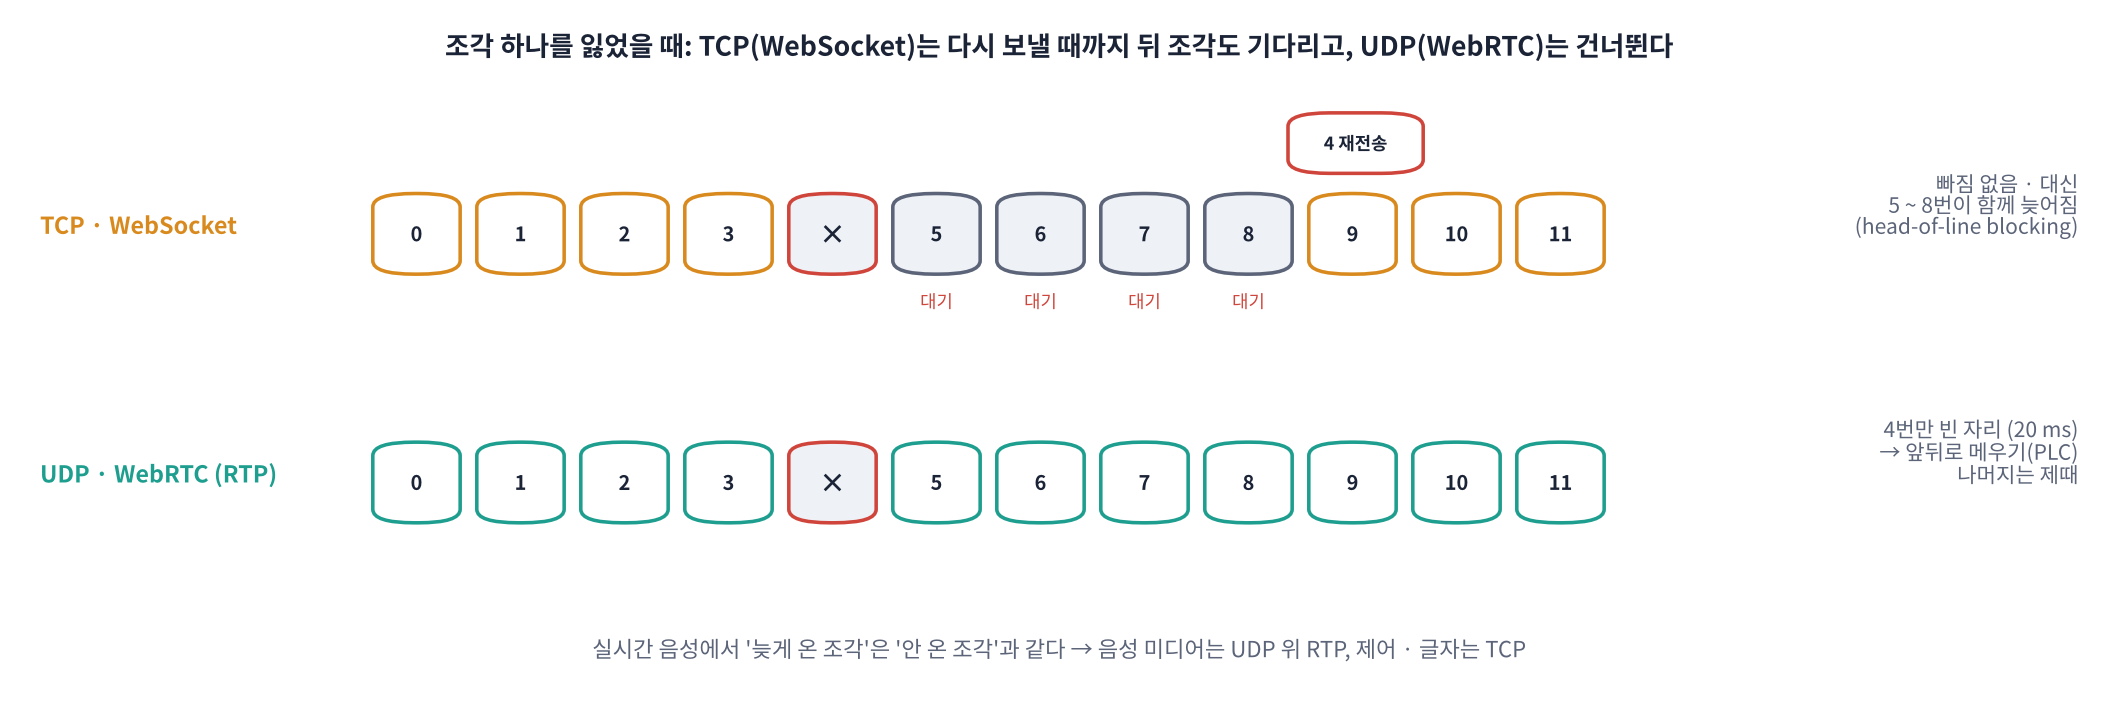

TCP(WebSocket의 바탕)는 **잃은 조각을 다시 보내고, 순서대로만** 넘겨줍니다. 빠짐은 없지만 다시 보내는 동안 **뒤 조각들까지 함께 기다립니다**(head-of-line blocking). UDP(WebRTC의 RTP)는 잃은 조각을 건너뛰고 나머지를 제때 넘깁니다.

> 🎬 **애니메이션 D26-5:** [TCP vs UDP](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#tcpudp) — 손실률 · 재전송 시간을 바꾸며 늦은 조각이 어떻게 몰리는지 보기

> ## 🎤 강사 스크립트 · TCP vs UDP  ⏱️ 4분
>
> 🖥️ [D26-5 TCP vs UDP](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#tcpudp): 손실 1 → 5%, 재전송 100 → 300 ms.
>
> 🗣️ "TCP는 성실한 우체국: 잃어버린 편지를 다시 보낼 때까지 뒤 편지도 붙잡아 둡니다. 실시간 음성에는 너무 성실하죠."

In [ ]:
# ✏️ 같은 손실률에서 TCP(WebSocket)와 UDP(WebRTC)의 늦은 조각 비교
LOSS, DELAY_MS = 0.03, 100                               # ✏️ 손실률 · 재생 지연
rows, AUD2 = [], {}
for tr in ["udp", "tcp"]:
    s_, a_, l_ = network(len(F), base_ms=BASE_MS, jitter_ms=JITTER_MS, loss=LOSS, transport=tr, seed=2)
    _, late = playout(s_, a_, DELAY_MS)
    fin = a_[np.isfinite(a_)] - s_[np.isfinite(a_)]
    rows.append(dict(전송=tr.upper(), 잃은조각=int(l_.sum()), 늦거나_빠진조각=int(late.sum()), 늦은조각_퍼센트=round(100 * late.mean(), 1),
                     최대지연_ms=round(float(fin.max()), 0)))
    AUD2[tr] = rebuild(F, late, "repeat")
    plt.plot(s_, np.where(np.isfinite(a_), a_ - s_, np.nan), label=tr.upper(), lw=1)
plt.axhline(DELAY_MS, color="red", ls="--", label="playout delay"); plt.xlabel("send time (ms)"); plt.ylabel("delay (ms)"); plt.legend()
plt.gcf().set_size_inches(9, 3); plt.tight_layout(); plt.show()
display(pd.DataFrame(rows))
play(AUD2["udp"], SR, "UDP: 잃은 조각만 메움"); play(AUD2["tcp"], SR, "TCP: 재전송 동안 뒤 조각까지 늦음")

> ## 🎤 강사 스크립트 · 비교 결과  ⏱️ 6분
>
> ✅ 예상(손실 3%, 재생 지연 100 ms): UDP 늦거나 빠진 조각 10% 안팎, TCP 30% 이상 · 최대 지연 300 ms 이상.
>
> 🎧 두 소리를 비교: UDP는 짧은 흠, TCP는 손실 뒤에 한 덩어리가 무너짐.

**❓ 생각해 보기**: 그렇다면 WebSocket(TCP)으로는 실시간 음성을 보내면 안 될까요?

<details>
<summary>답 보기</summary>

**보낼 수 있고, 실제로 많이 씁니다.** 서버 ↔ 서버처럼 **네트워크가 안정적이고 손실이 거의 없는 구간**(같은 데이터센터, 전화망 게이트웨이 ↔ 음성 서버)에서는 TCP도 지연이 작고 구현이 쉽습니다. 문제는 **와이파이 · 모바일처럼 손실이 잦은 사용자 쪽 구간**입니다. 그래서 흔한 구조는 '브라우저 · 앱 ↔ 서버는 WebRTC(UDP), 서버 ↔ 서버 · 전화 연동은 WebSocket'입니다(Part 6).

</details>

> 📝 **워크시트 2교시** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day26/worksheet.html) — 지연 · 지터 · 버퍼 · TCP vs UDP 10문항

> ## 🎤 강사 스크립트 · WebSocket 써도 되나 + 워크시트 2교시  ⏱️ 6분
>
> ❓ 생각해 보기 → 서버 ↔ 서버(안정된 구간)는 OK, 손실 많은 사용자 구간은 WebRTC.
>
> 🖥️ [worksheet.html 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day26/worksheet.html) 10문항.

## Part 3. Opus 코덱: 256 kbps → 24 kbps

**Opus**는 WebRTC의 기본 음성 코덱입니다. 사람이 덜 민감한 부분을 덜어내는 **손실 압축**이라 PCM의 10분의 1 이하로 줄어도 말을 알아듣는 데 지장이 거의 없습니다.

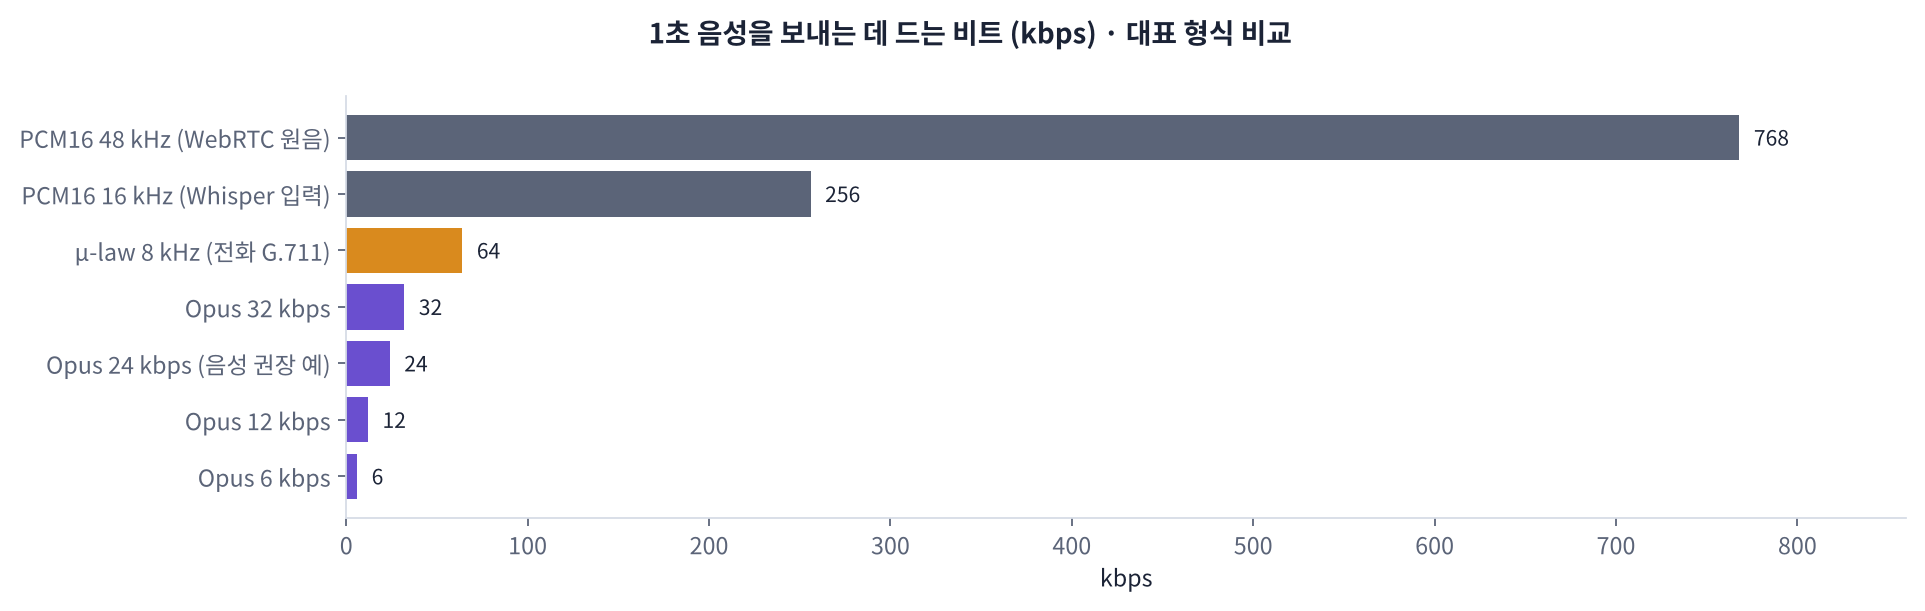

| Opus 특징 | 뜻 | 실시간에 좋은 점 |
|---|---|---|
| 6 ~ 510 kbps | 비트레이트를 상황에 맞게 | 네트워크가 나빠지면 낮추기 |
| 프레임 2.5 ~ 60 ms | 기본 20 ms | 지연이 작음 |
| 내부 48 kHz | 8 ~ 48 kHz 대역 지원 | 전화 품질부터 고음질까지 |
| `application=voip` | 음성에 맞춘 설정 | 말소리 명료도 우선 |
| FEC · DTX (선택) | 다음 패킷에 이전 정보 일부 · 침묵 때 덜 보내기 | 손실에 강함 · 대역폭 절약 |

> 💬 **쉽게 말하면**: 압축 파일(zip)은 원래대로 돌아오지만, Opus는 **귀가 눈치채지 못할 만큼만** 버립니다. 그래서 비교는 '숫자가 같나'가 아니라 **'들리나 · 받아쓰기가 되나'** 로 합니다.

> 🎬 **애니메이션 D26-6:** [비트레이트와 크기](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#opus) — 비트레이트 · 동시 통화 수를 바꾸며 1분 크기 · 대역폭 비교

### 🧩 빈칸 실습 6: Opus 비트레이트 설정
PyAV(`av`)의 인코더는 **초당 비트 수(bps)** 를 받습니다. `kbps` 변수로 `enc.bit_rate`를 정하세요.

> ## 🎤 강사 스크립트 · Part 3 Opus  ⏱️ 5분
>
> 🎯 **10분의 1로 줄여도 알아듣는다.**
>
> 🖥️ [D26-6 비트레이트와 크기](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#opus): 동시 통화 100 → 1,000.
>
> 🗣️ "Opus는 zip이 아닙니다. 원래로 돌아오지 않아요. 그래서 '같은가'가 아니라 '들리나 · 받아써지나'로 잽니다."

In [ ]:
# 🧩 빈칸 실습 6: Opus로 압축 → 패킷 → 복원 (PyAV · libopus)
def opus_roundtrip(y16, kbps, frame_ms=20):
    y48 = librosa.resample(to_np(y16), orig_sr=SR, target_sr=48000)     # Opus 내부는 48 kHz
    enc = av.CodecContext.create("libopus", "w")
    enc.sample_rate, enc.layout, enc.format = 48000, "mono", "s16"
    enc.bit_rate = ____                                                             # 빈칸 6: 초당 비트 수
    enc.options = {"application": "voip", "frame_duration": str(frame_ms)}
    enc.open()
    dec = av.CodecContext.create("libopus", "r"); dec.sample_rate, dec.layout = 48000, "mono"; dec.open()
    n = 48000 * frame_ms // 1000
    pcm = (np.clip(y48, -1, 1) * 32767).astype(np.int16)
    pcm = np.pad(pcm, (0, (-len(pcm)) % n))
    packets, out = [], []
    t0 = time.perf_counter()
    for i in range(0, len(pcm), n):
        fr = av.AudioFrame.from_ndarray(pcm[i:i + n][None, :], format="s16", layout="mono")
        fr.sample_rate, fr.pts, fr.time_base = 48000, i, fractions.Fraction(1, 48000)
        for p in list(enc.encode(fr)) + ([] if i + n < len(pcm) else list(enc.encode(None))):
            packets.append(bytes(p))
            out += [(lambda a: a / 32768 if np.issubdtype(a.dtype, np.integer) else a)(f.to_ndarray().reshape(-1)) for f in dec.decode(p)]
    sec = time.perf_counter() - t0
    y_out = np.concatenate(out).astype(np.float32)                     # int16로 나온 프레임은 위에서 [-1, 1]로 바꿈
    y_out = y_out[312:]                                  # Opus 앞부분 지연(pre-skip 6.5 ms) 잘라 맞추기
    return packets, librosa.resample(y_out, orig_sr=48000, target_sr=SR)[:len(y16)], sec

def mulaw_roundtrip(y16, mu=255):                        # 비교용: 전화망 G.711 μ-law (8 kHz · 8비트 = 64 kbps)
    y8 = librosa.resample(to_np(y16), orig_sr=SR, target_sr=8000)
    q = np.round((np.sign(y8) * np.log1p(mu * np.abs(np.clip(y8, -1, 1))) / np.log1p(mu) + 1) / 2 * 255)
    x = q / 255 * 2 - 1
    back = np.sign(x) * ((1 + mu) ** np.abs(x) - 1) / mu
    return librosa.resample(back.astype(np.float32), orig_sr=8000, target_sr=SR)[:len(y16)]

def mel_dist(a, b):                                      # 두 소리의 log-mel 차이 (작을수록 비슷)
    m = lambda y: np.log(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=64) + 1e-6)
    A, B = m(a), m(b); k = min(A.shape[1], B.shape[1])
    return float(np.mean(np.abs(A[:, :k] - B[:, :k])))

pk24, y24, _ = opus_roundtrip(VOICE, 24)
real24 = sum(map(len, pk24)) * 8 / (len(VOICE) / SR) / 1000
print(f"Opus 24 kbps: 패킷 {len(pk24)}개 · 평균 {np.mean([len(p) for p in pk24]):.0f} 바이트/패킷 · 실제 {real24:.1f} kbps")
check(12 <= real24 <= 36 and abs(len(y24) - len(VOICE)) < SR * 0.05, hint="빈칸 6 = kbps * 1000")

> ## 🎤 강사 스크립트 · 🧩 빈칸 6  ⏱️ 4분
>
> 🆘 "bit_rate의 단위는 bps. 24 kbps = ?" → `kbps * 1000`.
>
> ✅ `Opus 24 kbps: 패킷 ~160개 · 평균 40 ~ 60 바이트/패킷 · 실제 15 ~ 24 kbps`, ✅ (VBR이라 목표보다 낮게 나오는 것이 정상).

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
enc.bit_rate = kbps * 1000   # 빈칸 6
```

**해설**: 24 kbps = 24,000 bps. 20 ms 패킷 하나는 평균 약 60바이트(PCM16 16 kHz의 640바이트와 비교)입니다. 실제 비트레이트가 목표보다 꽤 낮게(예: 24 → 17 kbps) 나올 수 있는 것은 Opus가 **가변 비트레이트(VBR)** 라서 앞뒤 침묵처럼 조용한 부분에는 훨씬 적게, 복잡한 부분에는 더 쓰기 때문입니다. `bit_rate`는 '상한에 가까운 목표'로 생각하세요. `y_out[312:]`은 Opus 디코더가 앞에 붙이는 지연(pre-skip, 48 kHz에서 312샘플 = 6.5 ms)을 잘라 원음과 시간을 맞춥니다.

</details>

In [ ]:
# ✏️ 비트레이트별 크기 · 음질 · 받아쓰기 비교 (+ 전화 μ-law)
rows, AUD3 = [], {}
for k in [6, 12, 24, 32, 64]:
    pk, yk, sec = opus_roundtrip(VOICE, k)
    hyp = stt(yk); AUD3[k] = yk
    rows.append(dict(코덱=f"Opus {k}k", 실제_kbps=round(sum(map(len, pk)) * 8 / (len(VOICE) / SR) / 1000, 1), 패킷당_바이트=round(float(np.mean([len(p) for p in pk])), 0),
                     PCM대비=f"1/{256 / max(1e-9, sum(map(len, pk)) * 8 / (len(VOICE) / SR) / 1000):.0f}", 인코딩_RTF=round(sec / (len(VOICE) / SR), 3),
                     mel거리=round(mel_dist(VOICE, yk), 2), CER=round(cer(SAY, hyp), 3), 받아쓰기=hyp[:30]))
ymu = mulaw_roundtrip(VOICE); hyp = stt(ymu)
rows.append(dict(코덱="μ-law 8 kHz", 실제_kbps=64.0, 패킷당_바이트=160, PCM대비="1/4", 인코딩_RTF=None, mel거리=round(mel_dist(VOICE, ymu), 2), CER=round(cer(SAY, hyp), 3), 받아쓰기=hyp[:30]))
rows.append(dict(코덱="원음 PCM16", 실제_kbps=256.0, 패킷당_바이트=640, PCM대비="1/1", 인코딩_RTF=None, mel거리=0.0, CER=round(cer(SAY, stt(VOICE)), 3), 받아쓰기=stt(VOICE)[:30]))
CODEC = pd.DataFrame(rows); display(CODEC)
play(AUD3[6], SR, "Opus 6 kbps"); play(AUD3[24], SR, "Opus 24 kbps"); play(ymu, SR, "μ-law 8 kHz (전화)")

> ## 🎤 강사 스크립트 · 코덱 비교  ⏱️ 10분
>
> ✅ 예상: CER은 Opus 16k 이상에서 원음과 비슷, 6k에서 상승. μ-law는 mel거리가 Opus 12k보다 클 수 있음(4 kHz 위 잘림).
>
> 🎧 6k → 24k → μ-law 순서로. "전화 목소리가 왜 답답한지 들리죠?"
>
> ⚠️ 표의 CER 값은 TTS 목소리 · Whisper 크기에 따라 달라짐. 순서와 경향을 보기.

**❓ 생각해 보기**: 비트레이트를 계속 낮추면 받아쓰기(CER)는 언제부터 나빠질까요? 음성 비서에는 몇 kbps가 적당할까요?

<details>
<summary>답 보기</summary>

보통 Opus는 **16 ~ 24 kbps 이상**이면 받아쓰기가 원음과 거의 같고, **6 ~ 8 kbps**부터 자음 구분이 흐려져 CER이 오릅니다(표에서 직접 확인). 음성 비서는 사람이 듣는 것보다 **STT가 듣는 것**이 중요하므로 16 ~ 32 kbps 정도가 무난합니다. 전화(μ-law 8 kHz)는 4 kHz 위 소리를 잃어 'ㅅ · ㅆ · ㅈ' 같은 소리가 약해지므로, 전화 연동 비서는 **8 kHz용 STT 설정**이나 해당 조건 평가를 따로 해야 합니다(D11 · D14).

</details>

> ## 🎤 강사 스크립트 · 비트레이트 토론  ⏱️ 3분
>
> ❓ 생각해 보기 → 음성 비서는 'STT가 듣는 것' 기준으로 16 ~ 32 kbps. 전화 연동은 8 kHz 조건 평가 따로.

## Part 4. WebSocket: 조각을 보내고 이벤트를 받는 한 줄

**WebSocket**은 HTTP로 한 번 연결한 뒤, **양쪽이 아무 때나 메시지를 주고받는** 통로입니다(TCP 위). 실시간 음성에서는 보통 이렇게 씁니다.

| 방향 | 메시지 | 오늘 서버 |
|---|---|---|
| 클라이언트 → 서버 | **바이너리**: 20 ms 소리 조각 (PCM16 · μ-law · Opus) | `ws.send(bytes)` |
| 클라이언트 → 서버 | **텍스트(JSON)**: 설정 · 제어 (`{"codec": "opus"}`, `"end"`) | 첫 메시지 · 끝 |
| 서버 → 클라이언트 | **텍스트(JSON)**: 이벤트 (말 시작 · 끝, 받아쓰기 조각, 답 …) | `{"type": "frame", "rms_db": …, "event": "speech_start"}` |

> 💬 **쉽게 말하면**: 무전기처럼 한 번 연결해 두고 **소리는 바이너리 조각으로, 신호는 JSON 글자로** 주고받습니다.

> 👣 **한 단계씩**
> 1. 서버를 띄운다 (`ws_server.py`, 이 Colab 안 127.0.0.1)
> 2. 클라이언트가 연결하고 첫 메시지로 설정(JSON)을 보낸다
> 3. 20 ms마다 소리 조각(바이너리)을 **실시간 속도로** 보낸다
> 4. 서버는 조각마다 바로 분석해 이벤트(JSON)를 돌려준다 → 클라이언트는 **보내면서 동시에** 결과를 받는다
> 5. 끝 신호를 보내면 서버가 요약을 돌려준다

> 🎬 **애니메이션 D26-7:** [WebSocket 메시지 흐름](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#ws) — 바이너리 조각 · JSON 이벤트가 오가는 모습과 왕복 시간

> ## 🎤 강사 스크립트 · Part 4 WebSocket  ⏱️ 4분
>
> 🖥️ [D26-7 WebSocket 메시지 흐름](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#ws): 바이너리(소리) · 텍스트(JSON) 구분.
>
> 🗣️ "무전기처럼 한 번 연결하면 양쪽이 아무 때나 말합니다. 소리는 바이트로, 신호는 JSON으로."

In [ ]:
%%writefile ws_server.py
"""🔌 실시간 오디오 WebSocket 서버 (수업용) · 20 ms 조각을 받아 바로 분석해 이벤트를 돌려줍니다"""
import asyncio, json, sys, time
import numpy as np
from websockets.asyncio.server import serve

SR = 16000
THRESH_DB = -35                                          # 이보다 크면 '말소리'로 보는 단순 에너지 기준


def opus_decoder():
    import av
    dec = av.CodecContext.create("libopus", "r"); dec.sample_rate = 48000; dec.layout = "mono"; dec.open()
    return dec


async def handle(ws):
    cfg = json.loads(await ws.recv())                    # 첫 메시지: {"codec": "pcm" | "opus"}
    dec = opus_decoder() if cfg.get("codec") == "opus" else None
    seq, speaking, n_bytes, t0 = 0, False, 0, time.perf_counter()
    async for msg in ws:
        if isinstance(msg, str):                         # 글자 메시지 = 제어 (끝)
            await ws.send(json.dumps({"type": "summary", "frames": seq, "bytes": n_bytes, "sec": round(time.perf_counter() - t0, 3)}))
            break
        n_bytes += len(msg)
        if dec is None:
            x = np.frombuffer(msg, dtype=np.int16).astype(np.float32) / 32768
        else:
            import av
            arrs = [f.to_ndarray().reshape(-1) for f in dec.decode(av.Packet(msg))] or [np.zeros(1, np.int16)]
            x = np.concatenate(arrs).astype(np.float32)
            if np.issubdtype(arrs[0].dtype, np.integer): x = x / 32768   # int16로 나오면 [-1, 1]로
        rms_db = float(20 * np.log10(np.sqrt(np.mean(x ** 2)) + 1e-9))
        ev = {"type": "frame", "seq": seq, "rms_db": round(rms_db, 1)}
        if rms_db > THRESH_DB and not speaking:
            speaking = True; ev["event"] = "speech_start"
        elif rms_db <= THRESH_DB and speaking:
            speaking = False; ev["event"] = "speech_end"
        await ws.send(json.dumps(ev))
        seq += 1


async def main(port):
    async with serve(handle, "127.0.0.1", port, max_size=2 ** 20):
        await asyncio.Future()


if __name__ == "__main__":
    asyncio.run(main(int(sys.argv[1]) if len(sys.argv) > 1 else 8765))

> ## 🎤 강사 스크립트 · 서버 코드 읽기  ⏱️ 4분
>
> 🖥️ `handle()`: 첫 메시지 = 설정, `async for msg in ws` = 조각마다, `isinstance(msg, str)` = 제어. 에너지 기준 -35 dB로 말 시작 · 끝 이벤트.

In [ ]:
# 🚀 WebSocket 서버 띄우기 (자식 프로세스 · 이 Colab 안에서만)
if "WS_PROC" in globals(): WS_PROC.terminate()
WS_PORT = free_port()
WS_PROC = subprocess.Popen([sys.executable, "ws_server.py", str(WS_PORT)], stdout=subprocess.DEVNULL, stderr=open("ws_server.log", "w"))
print("서버 시작:", f"ws://127.0.0.1:{WS_PORT}", "· 준비됨" if wait_port(WS_PORT) else "· ⚠️ 시작 실패 → ws_server.log 확인")

> ## 🎤 강사 스크립트 · 서버 시작  ⏱️ 1분
>
> ✅ `서버 시작: ws://127.0.0.1:xxxxx · 준비됨`.

### 🧩 빈칸 실습 7: 소리 조각을 바이너리로 보내기
WebSocket은 `str`을 보내면 **텍스트 메시지**, `bytes`를 보내면 **바이너리 메시지**가 됩니다. int16 NumPy 배열을 **바이트로 바꾸는** 메서드 이름은? (`np.frombuffer`의 반대)

> ## 🎤 강사 스크립트 · 🧩 빈칸 7  ⏱️ 2분
>
> 🆘 "frombuffer의 반대, 바이트로 꺼내기" → `tobytes`.

In [ ]:
# 🧩 빈칸 실습 7: 20 ms 조각을 실시간 속도로 보내며 이벤트 받기
from websockets.asyncio.client import connect

async def ws_stream(chunks, codec="pcm", realtime=True):
    rtts, events = [], []
    async with connect(f"ws://127.0.0.1:{WS_PORT}") as ws:
        await ws.send(json.dumps({"codec": codec}))                       # 첫 메시지: 설정 (텍스트)
        t0 = time.perf_counter()
        for i, ch in enumerate(chunks):
            t = time.perf_counter()
            await ws.send(ch if isinstance(ch, bytes) else ch.____())                       # 빈칸 7: 배열 → 바이트
            ev = json.loads(await ws.recv()); rtts.append((time.perf_counter() - t) * 1000)
            if "event" in ev: events.append(dict(조각=ev["seq"], 시각_초=round(ev["seq"] * FRAME_MS / 1000, 2), 이벤트=ev["event"]))
            if realtime:                                                 # 실제 마이크처럼 20 ms마다 하나씩
                await asyncio.sleep(max(0, t0 + (i + 1) * FRAME_MS / 1000 - time.perf_counter()))
        await ws.send("end")                                             # 끝 신호 (텍스트)
        summary = json.loads(await ws.recv())
    return summary, rtts, events

PCM_CHUNKS = [(f * 32767).astype(np.int16) for f in F]
summary, rtts, events = await ws_stream(PCM_CHUNKS, "pcm")
print("서버 요약:", summary)
print(f"왕복 시간 p50 {np.percentile(rtts, 50):.2f} ms · p95 {np.percentile(rtts, 95):.2f} ms (같은 컴퓨터 안)")
display(pd.DataFrame(events[:6]))
check(summary["frames"] == len(PCM_CHUNKS) and summary["bytes"] == len(PCM_CHUNKS) * FRAME * 2 and any(e["이벤트"] == "speech_start" for e in events),
      hint="빈칸 7 = tobytes")

> ## 🎤 강사 스크립트 · 실시간 전송  ⏱️ 6분
>
> ✅ 예상: `서버 요약: {frames: 160 안팎, bytes: frames × 640, sec: 소리 길이}`, 왕복 p50 1 ~ 3 ms, 이벤트표(말 시작 0.5초 근처), ✅.
>
> 🗣️ "보내는 동안 이미 '말 시작' 이벤트가 돌아왔습니다. 이게 Part 1의 streaming이 네트워크 위에서 동작하는 모습입니다."

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
await ws.send(ch if isinstance(ch, bytes) else ch.tobytes())   # 빈칸 7
```

**해설**: `np.int16` 배열의 `tobytes()`는 메모리의 원래 바이트(리틀 엔디언 16비트)를 그대로 꺼냅니다. 서버는 `np.frombuffer(msg, dtype=np.int16)`로 되돌립니다. 양쪽이 **샘플링 레이트 · 비트 · 채널 · 엔디언**을 똑같이 알아야 하므로, 첫 텍스트 메시지에 형식을 적어 보내는 것이 관례입니다(전화망 연동 서비스들도 '8 kHz μ-law' 같은 형식을 미리 약속합니다).

</details>

In [ ]:
# ✏️ 같은 말을 Opus 패킷으로 보내기: 보낸 바이트 비교 (서버가 Opus를 풀어서 분석)
pk_opus, _, _ = opus_roundtrip(VOICE, 24)
s_opus, r_opus, e_opus = await ws_stream(pk_opus, "opus", realtime=False)
display(pd.DataFrame([dict(형식="PCM16 16 kHz", 조각=summary["frames"], 보낸_바이트=summary["bytes"], kbps=round(summary["bytes"] * 8 / (len(VOICE) / SR) / 1000, 1),
                           말시작_감지=[e["시각_초"] for e in events if e["이벤트"] == "speech_start"][:1]),
                      dict(형식="Opus 24 kbps", 조각=s_opus["frames"], 보낸_바이트=s_opus["bytes"], kbps=round(s_opus["bytes"] * 8 / (len(VOICE) / SR) / 1000, 1),
                           말시작_감지=[e["시각_초"] for e in e_opus if e["이벤트"] == "speech_start"][:1])]))

> ## 🎤 강사 스크립트 · Opus로 보내기  ⏱️ 4분
>
> ✅ 예상: PCM 102,400 바이트 vs Opus 약 7,000 바이트(15분의 1), 말 시작 감지는 둘 다 0.5초 근처.

**❓ 생각해 보기**: 같은 컴퓨터 안에서 왕복 시간이 1 ~ 2 ms였습니다. 실제 서비스에서는 이 숫자가 어떻게 바뀔까요? 무엇이 더해질까요?

<details>
<summary>답 보기</summary>

① **네트워크 왕복**: 같은 도시 10 ~ 30 ms, 다른 대륙 150 ms 이상. ② **TLS(wss://) 암호화**와 프록시. ③ 서버가 조각마다 하는 일(오늘은 RMS 계산뿐, 실제로는 VAD · 스트리밍 STT). ④ 손실이 있으면 TCP 재전송으로 **가끔 수백 ms 튐**(Part 2). 그래서 WebSocket 음성 서비스는 서버를 사용자 가까이 두고, 손실 많은 구간에서는 WebRTC를 씁니다.

</details>

> ## 🎤 강사 스크립트 · 실제 왕복 시간 토론  ⏱️ 3분
>
> ❓ 생각해 보기 → 네트워크 왕복 · TLS · 서버 처리 · TCP 재전송 튐.

> 📝 **워크시트 3교시** [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day26/worksheet.html) — Opus · WebSocket 10문항

> ## 🎤 강사 스크립트 · 워크시트 3교시  ⏱️ 5분
>
> 🖥️ [worksheet.html 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day26/worksheet.html) 10문항.

## Part 5. WebRTC 해부: offer · answer · ICE · DTLS · RTP

**WebRTC**는 브라우저 · 앱이 **서로 직접(또는 미디어 서버를 거쳐) 소리 · 영상을 주고받는** 표준입니다. 오늘은 파이썬 구현 `aiortc`로 **같은 Colab 안에 두 피어(pc1 → pc2)** 를 만들어 연결 과정을 하나씩 봅니다.

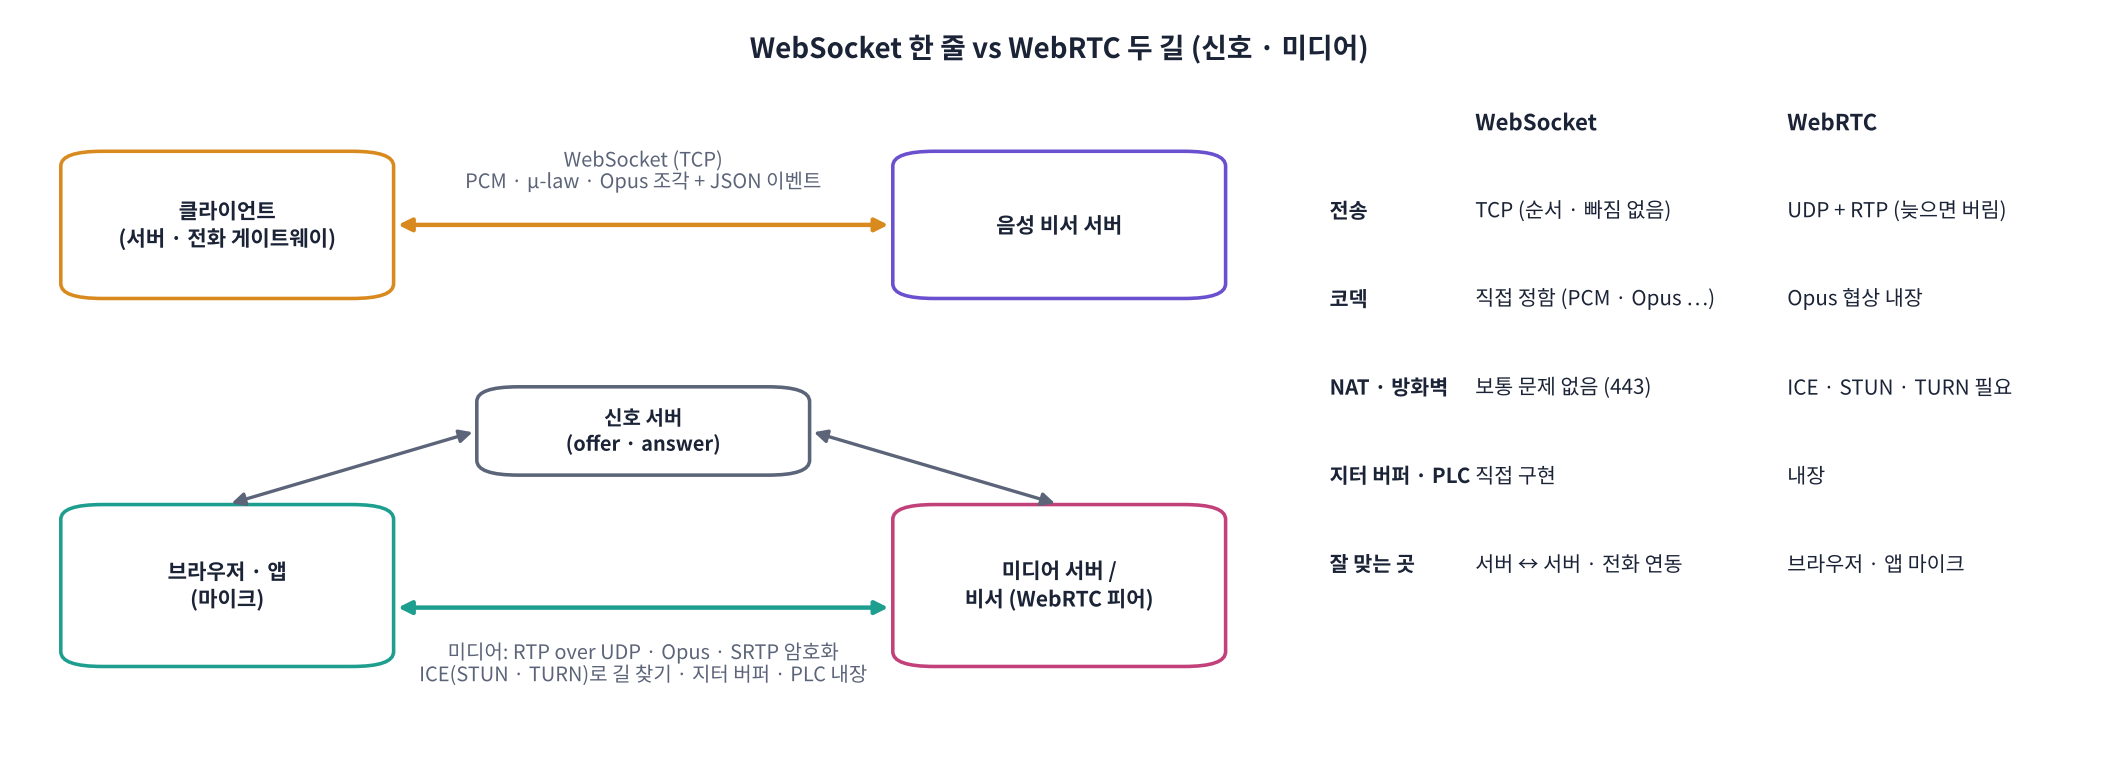

| 단계 | 무엇을 | 오늘 코드 |
|---|---|---|
| ① **offer** | pc1: "나는 Opus로 이런 소리를 보낼 수 있어" (SDP 글) | `pc1.createOffer()` → `setLocalDescription` |
| ② **신호 전달** | offer를 상대에게 전달 (WebSocket · HTTP 등 **아무 방법**) | 같은 프로그램이라 변수로 바로 전달 |
| ③ **answer** | pc2: "좋아, Opus로 받을게" | `pc2.setRemoteDescription(offer)` → `createAnswer()` |
| ④ **ICE** | 서로 닿는 주소 · 포트 찾기 (host · STUN · TURN 후보) | 오늘은 `127.0.0.1`만 |
| ⑤ **DTLS · SRTP** | 키를 나누고 미디어를 암호화 | 자동 |
| ⑥ **RTP** | 20 ms Opus 패킷이 UDP로 흐름 · 받는 쪽 지터 버퍼 | `getStats()`로 확인 |

> 💬 **쉽게 말하면**: 전화번호부(신호)로 서로의 연락처와 쓸 말(코덱)을 교환하고(offer · answer), 통할 길을 찾은 뒤(ICE), 암호를 맞추고(DTLS) 통화(RTP)를 시작합니다.

> 🍎 **비유: 국제 화상 회의 잡기.** 비서끼리 이메일(신호)로 '영어 · 화요일 3시 · 이 링크'를 정하고(offer · answer), 회의실 방화벽을 통과할 길을 찾고(ICE · TURN), 그다음에야 대화(RTP)가 시작됩니다. 이메일 자체로 대화하지는 않습니다.

> 🎬 **애니메이션 D26-8:** [WebRTC 연결 단계](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#rtc) — offer → answer → ICE → DTLS → RTP를 한 단계씩, 방화벽 · TURN 상황 바꾸기

### 🧩 빈칸 실습 8: answer 쪽에 offer 넣기
pc1이 offer를 만들어 **자기 설명(local description)** 으로 정했습니다. pc2는 그것을 **상대 설명(remote description)** 으로 받아야 answer를 만들 수 있습니다. pc1의 무엇을 넘길까요?

> ## 🎤 강사 스크립트 · Part 5 WebRTC  ⏱️ 8분
>
> 🎯 **신호(offer · answer)와 미디어(RTP)는 다른 길.**
>
> 🖥️ [D26-8 WebRTC 연결 단계](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#rtc): 단계를 넘기며, '회사 방화벽' 상황에서 TURN이 필요한 것 보여 주기.
>
> 🍎 "회의 일정을 이메일로 잡고(신호), 회의는 화상으로(미디어). 이메일로 대화하지 않습니다."

In [ ]:
# 🧩 빈칸 실습 8: aiortc 두 피어 연결 (pc1 → pc2, 오늘 소리를 Opus로 실시간 전송)
import aioice.ice
aioice.ice.get_host_addresses = lambda use_ipv4=True, use_ipv6=False: ["127.0.0.1"]   # 같은 컴퓨터 안 연결: 후보를 127.0.0.1로만
from aiortc import RTCPeerConnection, MediaStreamTrack
from aiortc.mediastreams import MediaStreamError

class ArrayTrack(MediaStreamTrack):                      # NumPy 소리를 20 ms 프레임으로 '실시간 속도'로 내보내는 트랙
    kind = "audio"
    def __init__(self, y16, ms=20):
        super().__init__()
        y48 = librosa.resample(to_np(y16), orig_sr=SR, target_sr=48000)
        self.pcm, self.n, self.i, self.t0 = (np.clip(y48, -1, 1) * 32767).astype(np.int16), 48000 * ms // 1000, 0, None
    async def recv(self):
        if self.i >= len(self.pcm):
            self.stop(); raise MediaStreamError
        if self.t0 is None: self.t0 = time.perf_counter()
        await asyncio.sleep(max(0, self.t0 + self.i / 48000 - time.perf_counter()))
        ch = np.pad(self.pcm[self.i:self.i + self.n], (0, max(0, self.i + self.n - len(self.pcm))))
        fr = av.AudioFrame.from_ndarray(ch[None, :], format="s16", layout="mono")
        fr.sample_rate, fr.pts, fr.time_base = 48000, self.i, fractions.Fraction(1, 48000)
        self.i += self.n
        return fr

async def rtc_loopback(y16, timeout_s=None):
    pc1, pc2 = RTCPeerConnection(), RTCPeerConnection()
    got, t_first, states = [], [], []
    pc1.on("connectionstatechange", lambda: states.append(("pc1", pc1.connectionState, round(time.perf_counter() - T0, 3))))
    @pc2.on("track")
    def on_track(track):
        async def pull():
            try:
                while True:
                    f = await track.recv()
                    if not t_first: t_first.append(time.perf_counter() - T0)
                    got.append(f.to_ndarray())
            except MediaStreamError:
                pass
        asyncio.ensure_future(pull())
    pc1.addTrack(ArrayTrack(y16))
    T0 = time.perf_counter()
    await pc1.setLocalDescription(await pc1.createOffer())                # ① offer
    offer_sdp = pc1.localDescription.sdp
    await pc2.setRemoteDescription(pc1.____)                                       # 빈칸 8: ② 신호 전달 (offer를 pc2에)
    await pc2.setLocalDescription(await pc2.createAnswer())               # ③ answer
    await pc1.setRemoteDescription(pc2.localDescription)
    t_end = time.perf_counter() + (timeout_s or len(y16) / SR + 8)
    last_n, quiet = -1, 0
    while time.perf_counter() < t_end:                                    # 소리가 다 건너올 때까지 (0.5초 동안 새 프레임이 없으면 끝)
        await asyncio.sleep(0.1)
        quiet = quiet + 1 if len(got) == last_n and got else 0
        last_n = len(got)
        if quiet >= 5: break
    stats = {"outbound-rtp": next((s for s in (await pc1.getStats()).values() if s.type == "outbound-rtp"), None),
             "inbound-rtp": next((s for s in (await pc2.getStats()).values() if s.type == "inbound-rtp"), None)}
    await pc1.close(); await pc2.close()
    return dict(offer=offer_sdp, answer=pc2.localDescription.sdp if pc2.localDescription else "", frames=got, first=t_first[0] if t_first else None,
                states=states, stats=stats, sec=time.perf_counter() - T0)

RTC = await rtc_loopback(VOICE)
sdp_lines = [l for l in RTC["offer"].splitlines() if l.startswith(("m=audio", "a=rtpmap:96", "a=candidate", "a=fingerprint", "a=setup", "a=sendrecv", "a=sendonly"))]
print("📜 offer SDP 중 일부:\n  " + "\n  ".join(l[:90] for l in sdp_lines))
print("🔗 연결 상태 변화:", RTC["states"])
ok_media = len(RTC["frames"]) > 0
if ok_media:
    rx = np.concatenate([f.reshape(-1, 2).mean(1) if f.shape[-1] == 1920 else f.reshape(-1) for f in RTC["frames"]]).astype(np.float32) / 32768
    RX16 = librosa.resample(rx, orig_sr=48000, target_sr=SR)
    o, i = RTC["stats"].get("outbound-rtp"), RTC["stats"].get("inbound-rtp")
    display(pd.DataFrame([dict(보낸_패킷=o.packetsSent, 보낸_바이트=o.bytesSent, 실제_kbps=round(o.bytesSent * 8 / (len(VOICE) / SR) / 1000, 1),
                               받은_패킷=i.packetsReceived, 잃은_패킷=i.packetsLost, 지터_ms=round(i.jitter / 48, 2), 첫_소리까지_초=round(RTC["first"], 3))]))
    play(RX16, SR, "WebRTC로 건너온 소리 (Opus · 48 kHz → 16 kHz)")
else:
    print("⚠️ 이 환경에서는 미디어가 흐르지 않았습니다(방화벽 · UDP 제한 가능). SDP · 연결 단계는 위에서 확인하고, 애니메이션 D26-8로 이어서 보세요.")
check("opus/48000" in RTC["offer"] and "a=fingerprint" in RTC["offer"] and RTC["answer"] != "", hint="빈칸 8 = localDescription")

> ## 🎤 강사 스크립트 · 🧩 빈칸 8 · 연결 결과  ⏱️ 10분
>
> 🆘 "pc1이 자기 것으로 정한 설명 = local ___" → `localDescription`.
>
> ✅ 예상: SDP 줄(m=audio … · rtpmap:96 opus/48000/2 · candidate 127.0.0.1 · fingerprint · setup:actpass), 연결 상태 connecting → connected(0.1초 안), 통계표(보낸 = 받은 패킷 약 160, 잃은 0, 지터 1 ms 안팎, 첫 소리 0.1초 안팎), 🎧 건너온 소리, ✅.
>
> ⚠️ 실제 kbps가 50 이상으로 나오는 것은 aiortc 기본 Opus 비트레이트 + RTP 머리말 때문. Part 6 대역폭 계산과 연결.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
await pc2.setRemoteDescription(pc1.localDescription)   # 빈칸 8
```

**해설**: WebRTC 연결은 '내 설명(local)'과 '상대 설명(remote)'을 서로 맞바꾸는 것입니다. pc1의 local = pc2의 remote, pc2의 local(answer) = pc1의 remote. 실제 서비스에서는 이 두 글(SDP)을 **신호 서버**(WebSocket · HTTP)가 전달합니다. SDP의 `a=rtpmap:96 opus/48000/2`는 'Opus · 48 kHz · 2채널'로 보내겠다는 뜻이고, `a=fingerprint`는 DTLS 암호화 인증서의 지문, `a=candidate`는 ICE 후보 주소입니다. 받은 프레임이 (1, 1920)인 것은 48 kHz 20 ms(960샘플) × 2채널이 섞여 있기 때문입니다.

</details>

**❓ 생각해 보기**: 오늘은 두 피어가 같은 컴퓨터라 127.0.0.1로 바로 연결됐습니다. 집 와이파이의 브라우저와 클라우드 서버를 연결할 때는 무엇이 더 필요할까요?

<details>
<summary>답 보기</summary>

① **신호 서버**: offer · answer · 후보를 전달할 통로(보통 WebSocket · HTTPS). ② **STUN**: '바깥에서 보이는 내 주소'를 알려 주는 서버 → NAT 뒤에서도 후보를 만든다. ③ **TURN**: 회사 방화벽 등으로 직접 길이 막히면 **중계**해 주는 서버(대역폭 비용 발생). ④ HTTPS 페이지(브라우저는 마이크 권한을 안전한 출처에서만 줌). LiveKit 같은 미디어 서버(D29 ~ D30)는 이런 것들을 한데 묶어 제공합니다.

</details>

> ## 🎤 강사 스크립트 · 실제 환경 토론  ⏱️ 3분
>
> ❓ 생각해 보기 → 신호 서버 · STUN · TURN · HTTPS. "LiveKit이 이걸 다 해 줍니다(D29)."

## Part 6. 둘 중 무엇을 쓸까 · 대역폭 계산

| 상황 | 추천 | 이유 |
|---|---|---|
| 브라우저 · 모바일 앱의 마이크 ↔ 음성 비서 | **WebRTC** | 손실 많은 구간 · 지터 버퍼 · PLC · 에코 제거 · Opus 내장 |
| 전화망(SIP 게이트웨이) ↔ 음성 서버 | **WebSocket** (μ-law 8 kHz 조각) 또는 RTP | 서버 ↔ 서버, 안정된 구간, 구현이 쉬움 |
| 음성 서버 ↔ STT · TTS · LLM 클라우드 API | **WebSocket** | 스트리밍 API 대부분이 WebSocket 제공 |
| 여러 사람이 한 방에 (회의 · 상담 이관) | **WebRTC + 미디어 서버 (SFU)** | 방 · 참가자 · 녹음 관리 → LiveKit (D29) |

> 💬 **쉽게 말하면**: **사람 쪽 마지막 구간은 WebRTC, 서버끼리는 WebSocket**이 흔한 조합입니다. 일부 Speech-to-Speech API는 두 방식을 모두 제공합니다(D30).

> 🎬 **애니메이션 D26-9:** [무엇을 쓸까](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#choose) — 상황 카드를 골라 WebSocket · WebRTC를 고르고 이유 확인

### 🧩 빈칸 실습 9: 동시 통화 대역폭
패킷마다 **머리말(IP 20 + UDP 8 + RTP 12 = 40바이트)** 이 붙습니다. 20 ms마다 40바이트면 **16 kbps**나 됩니다(Opus 24 kbps와 비슷!). 통화는 **보내고 받는 양방향**이므로 한 통화의 대역폭은 `(코덱 + 머리말) × ____`.

> ## 🎤 강사 스크립트 · Part 6 선택  ⏱️ 4분
>
> 🖥️ [D26-9 무엇을 쓸까](https://imguru-mooc.github.io/AI_Voice/day26/animation.html#choose): 상황 카드 5장.
>
> 🗣️ "사람 쪽 마지막 구간은 WebRTC, 서버끼리는 WebSocket. 이번 주 Pipecat · LiveKit도 이 구조입니다."

In [ ]:
# 🧩 빈칸 실습 9: 동시 통화 N개에 필요한 대역폭 (서버 쪽)
HEADER_BYTES = 40                                        # IP 20 + UDP 8 + RTP 12 (암호화 · 확장 머리말 제외)
overhead_kbps = HEADER_BYTES * 8 * (1000 / FRAME_MS) / 1000   # 패킷 머리말 비용 (20 ms → 16 kbps)

def call_kbps(codec_kbps):
    return (codec_kbps + overhead_kbps) * ____                                         # 빈칸 9: 양방향

N_CALLS = 100                                            # ✏️ 동시 통화 수
BW = pd.DataFrame([dict(코덱=n, 코덱_kbps=k, 통화당_kbps=call_kbps(k), 동시통화=N_CALLS, 합계_Mbps=round(call_kbps(k) * N_CALLS / 1000, 1))
                   for n, k in [("PCM16 16 kHz", 256), ("μ-law 8 kHz", 64), ("Opus 32k", 32), ("Opus 24k", 24), ("Opus 12k", 12)]])
display(BW)
check(overhead_kbps == 16 and call_kbps(24) == 80 and BW.loc[BW["코덱"] == "Opus 24k", "합계_Mbps"].item() == 8.0, hint="빈칸 9 = 2 (보내기 + 받기)")

> ## 🎤 강사 스크립트 · 🧩 빈칸 9 대역폭  ⏱️ 4분
>
> 🆘 "통화는 보내기 + 받기" → `2`.
>
> ✅ 표: Opus 24k 통화당 80 kbps · 100통화 8 Mbps, PCM16 54.4 Mbps, ✅.
>
> ❓ "머리말 16 kbps가 Opus 24 kbps와 맞먹는다. 줄이려면?" → 프레임 40 ms(지연 ↑), 헤더 압축.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return (codec_kbps + overhead_kbps) * 2   # 빈칸 9
```

**해설**: Opus 24 kbps + 머리말 16 kbps = 40 kbps, 양방향이면 80 kbps. 100통화면 8 Mbps입니다. 같은 100통화를 PCM16으로 보내면 54 Mbps로 7배 가까이 됩니다. 프레임을 40 ms로 늘리면 머리말이 8 kbps로 줄지만 지연이 20 ms 늘어납니다(Part 1의 맞바꿈). 실제로는 SRTP 인증 태그 · RTP 확장 · TURN 중계 등이 더해지므로 여유를 두고 계획합니다.

</details>

## Part 7. 정리 · 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| Streaming | 다 모으지 않고 20 ms 조각으로 흘려보낸다 | `FRAME = SR * FRAME_MS / 1000` |
| 비트레이트 | 샘플링 레이트 × 비트 × 채널 | PCM16 16 kHz = 256 kbps |
| 지터 · 버퍼 | 늦은 조각은 버리고 메운다, 버퍼 = 끊김 ↔ 지연 맞바꿈 | `deadline = send + delay_ms` |
| 적응형 버퍼 | 지난 지연의 높은 백분위로 | `np.percentile(obs, 95)` |
| TCP vs UDP | TCP는 빠짐 없이 늦게, UDP는 제때 빠짐 있게 | head-of-line blocking |
| Opus | 20 ms · 6 ~ 64 kbps · 음성은 16 ~ 32 kbps면 받아쓰기 유지 | `enc.bit_rate = kbps * 1000` |
| WebSocket | 바이너리 조각 + JSON 이벤트, 서버 ↔ 서버에 적합 | `ws.send(chunk.tobytes())` |
| WebRTC | offer · answer · ICE · DTLS · RTP, 사람 쪽 구간에 적합 | `setRemoteDescription(pc1.localDescription)` |
| 대역폭 | (코덱 + 머리말) × 2 × 통화 수 | 100통화 Opus 24k ≈ 8 Mbps |

### 📝 과제
1. **내 네트워크 재기**: 휴대폰 핫스팟 · 집 와이파이에서 `ping -c 50 8.8.8.8`(또는 Colab에서 가까운 서버)의 지연 · 표준편차를 재고, Part 2의 `BASE_MS · JITTER_MS`에 넣어 늦은 조각 5% 이하가 되는 재생 지연을 구하세요.
2. **PLC 비교**: `rebuild()`의 무음 · 반복 외에 **앞뒤 조각 사이를 부드럽게 잇는(crossfade)** 방법을 만들어 손실 5%에서 세 방법을 들어 보고 CER을 비교하세요.
3. **WebSocket 서버 확장**: `ws_server.py`가 말 끝(`speech_end`)마다 그 구간 소리를 모아 Whisper로 받아쓰고 `{"type": "transcript", ...}` 이벤트를 돌려주게 바꿔 보세요(D27 Pipecat의 STT 서비스가 하는 일).

### ✅ 개념 워크시트 제출
> 📝 **[D26 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day26/worksheet.html)** — 4교시 × 10문항. 4개 탭 채점 → 제출 → 📋 캡처 → 노션. **버퍼 크기별 늦은 조각표 · 코덱 비교표 · WebSocket 왕복 시간 · WebRTC 통계표 · 대역폭 표**도 함께 붙이세요.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day26/animation.html) — D26-1 ~ D26-9

### 다음 시간 (D27 · Pipecat 기초)
오늘 손으로 만든 조각(Frame) · 흐름(Stream) · 통로(Transport: WebSocket · WebRTC)를 **Pipecat**이 한 틀로 묶습니다. **Pipeline · Frame · Processor · Transport** 구조로 VAD → STT → LLM → TTS를 이어, 말하는 도중에도 결과가 흐르는 비서를 만듭니다.

> ## 🎤 강사 스크립트 · Part 7 정리  ⏱️ 5분
>
> 🎯 **오늘 한 줄: 조각으로 흘려보내고, 늦은 조각은 버리고 메우고, 작게 압축해서, 길에 맞는 통로로 보낸다.**
>
> 🖥️ [worksheet.html 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day26/worksheet.html) → 채점 → 제출 → 📋 캡처 → 노션.
>
> ➡️ "내일은 Pipecat입니다. 오늘 손으로 만든 프레임 · 흐름 · 통로를 Frame · Pipeline · Transport라는 이름으로 묶어, VAD → STT → LLM → TTS를 흘려보냅니다."

In [ ]:
# 🧹 정리: WebSocket 서버 끄기
if "WS_PROC" in globals():
    WS_PROC.terminate(); WS_PROC.wait(timeout=5)
print("서버 종료 · 로그:", (open("ws_server.log").read()[-200:] or "(없음)"))

> ## 🎤 강사 스크립트 · 정리  ⏱️ 1분
>
> ✅ `서버 종료 · 로그: (없음)`.